# AI-Powered Network Intrusion Detection System

## Notebook 06 – SHAP Explainability for Random Forest Model

**Author:** Jithesh  
**Role:** Member A – ML & Data Engineer  
**Dataset:** CICIDS-2017  
**Model:** Random Forest Classifier  
**Explainability Method:** SHAP (SHapley Additive exPlanations)

---

### Purpose

The purpose of this notebook is to integrate SHAP (SHapley Additive exPlanations) with the trained Random Forest intrusion detection model developed in Notebook 05.

The notebook focuses on interpreting the predictions made by the Random Forest model through global feature importance and local prediction explanations.

The persisted Random Forest model and feature metadata generated during the previous modelling stage are treated as read-only inputs. The model is not retrained in this notebook.

---

### Notebook Objective

This notebook continues from Notebook 05 and uses the persisted Random Forest model and associated feature metadata.

The main objectives are to:

1. Load and verify the persisted Random Forest model.
2. Recover the authoritative feature names and model configuration.
3. Configure the SHAP explanation framework.
4. Generate global feature importance explanations.
5. Analyze the contribution of individual features to model predictions.
6. Generate local explanations for representative intrusion predictions.
7. Validate the SHAP explanation outputs.
8. Persist SHAP explanation artifacts for downstream dashboard integration.
9. Establish a reproducible explainability handoff for subsequent development.

The trained Random Forest model is treated as a read-only artifact and is not modified or retrained by this notebook.

## 6.1 Environment Setup

This section initializes the Colab environment, mounts Google Drive, verifies the required project directories, and imports the libraries required for SHAP-based Random Forest explainability.

The notebook reuses the established Google Drive project structure from the previous modelling notebooks.

Unlike Notebook 05, this notebook does not retrain the Random Forest model. The persisted Random Forest handoff artifact is loaded directly from Google Drive.

A single environment and recovery cell is used so that, after a Colab runtime restart, the required environment, project paths, model, and feature metadata can be restored without repeating model training or data preparation.

In [1]:
# ============================================================
# 6.1 Environment Setup
# ============================================================

import os
import sys
import json
import gc
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

# ------------------------------------------------------------
# Google Drive
# ------------------------------------------------------------

from google.colab import drive

drive.mount("/content/drive")

# ------------------------------------------------------------
# Install / verify SHAP
# ------------------------------------------------------------

!pip install -q shap

import shap

# ------------------------------------------------------------
# Project paths
# ------------------------------------------------------------

PROJECT_PATH = (
    "/content/drive/MyDrive/"
    "AI-Network-Intrusion-Detection-System"
)

DATA_PATH = os.path.join(
    PROJECT_PATH,
    "data"
)

OUTPUTS_PATH = os.path.join(
    PROJECT_PATH,
    "outputs"
)

MODEL_PREP_PATH = os.path.join(
    OUTPUTS_PATH,
    "model_preparation"
)

MODELS_PATH = os.path.join(
    PROJECT_PATH,
    "trained_models"
)

SHAP_OUTPUT_PATH = os.path.join(
    OUTPUTS_PATH,
    "shap"
)

# Create SHAP output directory if required
os.makedirs(
    SHAP_OUTPUT_PATH,
    exist_ok=True
)

# ------------------------------------------------------------
# Persisted Random Forest handoff
# ------------------------------------------------------------

RF_HANDOFF_PATH = os.path.join(
    MODELS_PATH,
    "random_forest_handoff.joblib"
)

# ------------------------------------------------------------
# Feature metadata
# ------------------------------------------------------------

FEATURE_METADATA_PATH = os.path.join(
    MODEL_PREP_PATH,
    "feature_metadata.json"
)

# ------------------------------------------------------------
# Test data
# ------------------------------------------------------------

X_TEST_PATH = os.path.join(
    MODEL_PREP_PATH,
    "X_test_scaled.npy"
)

Y_TEST_PATH = os.path.join(
    MODEL_PREP_PATH,
    "y_test.npy"
)

# ------------------------------------------------------------
# Verify required artifacts
# ------------------------------------------------------------

required_artifacts = {
    "Random Forest handoff":
        RF_HANDOFF_PATH,

    "Feature metadata":
        FEATURE_METADATA_PATH,

    "Test feature matrix":
        X_TEST_PATH,

    "Test target array":
        Y_TEST_PATH
}

print("=" * 70)
print("SHAP EXPLAINABILITY ENVIRONMENT SETUP")
print("=" * 70)

print("\nProject path:")
print(PROJECT_PATH)

print("\nChecking required artifacts:")

for artifact_name, artifact_path in required_artifacts.items():

    if not os.path.exists(artifact_path):

        raise FileNotFoundError(
            f"\nRequired artifact not found:\n"
            f"{artifact_path}"
        )

    print(
        f"✓ {artifact_name}: "
        f"{os.path.basename(artifact_path)}"
    )

# ------------------------------------------------------------
# Load persisted Random Forest handoff
# ------------------------------------------------------------

print("\nLoading persisted Random Forest handoff...")

rf_handoff = joblib.load(
    RF_HANDOFF_PATH
)

# ------------------------------------------------------------
# Load feature metadata
# ------------------------------------------------------------

with open(
    FEATURE_METADATA_PATH,
    "r"
) as f:

    feature_metadata = json.load(f)

# ------------------------------------------------------------
# Display SHAP environment
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("RECOVERED SHAP ENVIRONMENT")
print("=" * 70)

print("\nSHAP version:")
print(shap.__version__)

print("\nRandom Forest handoff type:")
print(type(rf_handoff).__name__)

print("\nFeature metadata loaded:")
print("Dataset:",
      feature_metadata.get("dataset"))

print(
    "Number of features:",
    feature_metadata.get("number_of_features")
)

print(
    "Target column:",
    feature_metadata.get("target_column")
)

print("\nSHAP output path:")
print(SHAP_OUTPUT_PATH)

print("\nEnvironment setup completed successfully.")

print("=" * 70)

Mounted at /content/drive
SHAP EXPLAINABILITY ENVIRONMENT SETUP

Project path:
/content/drive/MyDrive/AI-Network-Intrusion-Detection-System

Checking required artifacts:
✓ Random Forest handoff: random_forest_handoff.joblib
✓ Feature metadata: feature_metadata.json
✓ Test feature matrix: X_test_scaled.npy
✓ Test target array: y_test.npy

Loading persisted Random Forest handoff...

RECOVERED SHAP ENVIRONMENT

SHAP version:
0.52.0

Random Forest handoff type:
dict

Feature metadata loaded:
Dataset: CICIDS2017
Number of features: 63
Target column: Target

SHAP output path:
/content/drive/MyDrive/AI-Network-Intrusion-Detection-System/outputs/shap

Environment setup completed successfully.


In [2]:
# ------------------------------------------------------------
# SHAP analysis objects
# ------------------------------------------------------------

# Load Random Forest handoff bundle
rf_handoff = joblib.load(RF_HANDOFF_PATH)

# Recover the trained Random Forest
model = rf_handoff["model"]

# Recover authoritative feature ordering
feature_names = rf_handoff["feature_names"]

# Load the already-scaled test matrix
X_test = np.load(
    X_TEST_PATH,
    mmap_mode="r"
)

# Load test targets
y_test = np.load(Y_TEST_PATH)

print("\nSHAP analysis objects recovered:")
print("Model type      :", type(model).__name__)
print("Test matrix     :", X_test.shape)
print("Test targets    :", y_test.shape)
print("Feature count   :", len(feature_names))


SHAP analysis objects recovered:
Model type      : RandomForestClassifier
Test matrix     : (566149, 63)
Test targets    : (566149,)
Feature count   : 63


## 6.2 Random Forest Handoff Validation

### Purpose

The Random Forest model developed in the previous modelling stage is loaded from its persisted handoff artifact.

Before performing explainability analysis, the handoff structure is inspected and validated to identify the stored model, feature metadata, and other persisted components.

This step ensures that SHAP explanations are generated using the exact trained model and feature representation used during model evaluation.

The persisted Random Forest artifact is treated as read-only.

In [3]:
# ============================================================
# 6.2 Random Forest Handoff Validation
# ============================================================

print("=" * 70)
print("RANDOM FOREST HANDOFF VALIDATION")
print("=" * 70)

# ------------------------------------------------------------
# Inspect handoff structure
# ------------------------------------------------------------

print("\nHandoff object type:")
print(type(rf_handoff).__name__)

print("\nHandoff keys:")

if isinstance(rf_handoff, dict):

    for key in rf_handoff.keys():
        print(f"  ✓ {key}")

else:

    print("Handoff is not a dictionary.")

# ------------------------------------------------------------
# Inspect stored components
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("STORED COMPONENTS")
print("-" * 70)

if isinstance(rf_handoff, dict):

    for key, value in rf_handoff.items():

        print(f"\n[{key}]")
        print("Type:", type(value).__name__)

        # Print useful structural information
        if hasattr(value, "shape"):
            print("Shape:", value.shape)

        if isinstance(value, (list, tuple)):
            print("Length:", len(value))

        if isinstance(value, dict):
            print("Nested keys:", list(value.keys()))

# ------------------------------------------------------------
# Locate Random Forest model
# ------------------------------------------------------------

rf_model = None

if isinstance(rf_handoff, dict):

    possible_model_keys = [
        "model",
        "rf_model",
        "random_forest",
        "classifier"
    ]

    for key in possible_model_keys:

        if key in rf_handoff:

            candidate = rf_handoff[key]

            # Verify that candidate behaves like a fitted sklearn model
            if hasattr(candidate, "predict"):

                rf_model = candidate

                print(
                    f"\n✓ Random Forest model located under key: "
                    f"'{key}'"
                )

                break

if rf_model is None:

    raise ValueError(
        "Could not automatically locate the trained "
        "Random Forest model inside the handoff."
    )

# ------------------------------------------------------------
# Validate model properties
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("MODEL VALIDATION")
print("-" * 70)

print("\nModel type:")
print(type(rf_model).__name__)

if hasattr(rf_model, "n_estimators"):
    print("Number of estimators:",
          rf_model.n_estimators)

if hasattr(rf_model, "n_features_in_"):
    print("Number of input features:",
          rf_model.n_features_in_)

if hasattr(rf_model, "classes_"):
    print("Classes:")
    print(rf_model.classes_)

# ------------------------------------------------------------
# Validate against feature metadata
# ------------------------------------------------------------

expected_features = feature_metadata.get(
    "number_of_features"
)

print("\nExpected number of features:",
      expected_features)

if hasattr(rf_model, "n_features_in_"):

    actual_features = rf_model.n_features_in_

    if actual_features != expected_features:

        raise ValueError(
            f"Feature mismatch detected: "
            f"model expects {actual_features}, "
            f"metadata contains {expected_features}."
        )

    print(
        f"✓ Feature count validated: "
        f"{actual_features}"
    )

# ------------------------------------------------------------
# Final validation status
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("RANDOM FOREST HANDOFF VALIDATION COMPLETED")
print("=" * 70)

print("\nThe persisted Random Forest model is ready for")
print("SHAP explainability analysis.")

RANDOM FOREST HANDOFF VALIDATION

Handoff object type:
dict

Handoff keys:
  ✓ model
  ✓ feature_names
  ✓ n_features
  ✓ n_classes
  ✓ model_type
  ✓ dataset
  ✓ target_column

----------------------------------------------------------------------
STORED COMPONENTS
----------------------------------------------------------------------

[model]
Type: RandomForestClassifier

[feature_names]
Type: list
Length: 63

[n_features]
Type: int

[n_classes]
Type: int

[model_type]
Type: str

[dataset]
Type: str

[target_column]
Type: str

✓ Random Forest model located under key: 'model'

----------------------------------------------------------------------
MODEL VALIDATION
----------------------------------------------------------------------

Model type:
RandomForestClassifier
Number of estimators: 100
Number of input features: 63
Classes:
[ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14]

Expected number of features: 63
✓ Feature count validated: 63

RANDOM FOREST HANDOFF VALIDATION COMPLETED

T

## 6.3 Global Feature Importance Visualization

Global feature importance analysis explains which input features have the greatest overall influence on the Random Forest model's predictions.

Using SHAP (SHapley Additive exPlanations), we will calculate the contribution of each feature across the test dataset and visualize the overall importance of the network traffic features.

This analysis helps us:

- Identify the most influential features used by the model.
- Understand the overall decision-making behavior of the Random Forest.
- Compare SHAP-based importance with the model's native feature importance.
- Provide interpretable insights for the intrusion detection system.

GLOBAL SHAP FEATURE IMPORTANCE ANALYSIS

Validating SHAP analysis environment...
✓ model
✓ X_test
✓ feature_names

SHAP input validation completed.

SHAP SAMPLE CONFIGURATION

Available test samples : 566,149
Samples selected      : 500
Number of features    : 63

✓ SHAP sample prepared
SHAP input shape: (500, 63)

CREATING SHAP TREEEXPLAINER

✓ TreeExplainer created successfully
Explainer creation time: 0.57 seconds

CALCULATING SHAP VALUES

✓ SHAP values calculated successfully
Calculation time: 583.96 seconds

SHAP output type:
<class 'numpy.ndarray'>

SHAP OUTPUT VALIDATION

SHAP array shape: (500, 63, 15)

Normalized SHAP array shape: (500, 63, 15)

CALCULATING GLOBAL FEATURE IMPORTANCE

TOP 20 FEATURES BY GLOBAL SHAP IMPORTANCE


,rank,feature,mean_absolute_shap_value
0,1,Destination Port,0.015238
1,2,Down/Up Ratio,0.008418
2,3,Flow IAT Max,0.008054
3,4,Idle Max,0.005140
4,5,Bwd Packet Length Mean,0.004795
5,6,Avg Fwd Segment Size,0.004307
6,7,Fwd Packet Length Max,0.004228
7,8,Fwd IAT Total,0.004005
8,9,Active Mean,0.003917
9,10,Average Packet Size,0.003849



✓ Global SHAP importance saved:
/content/drive/MyDrive/AI-Network-Intrusion-Detection-System/outputs/shap/global_shap_feature_importance.csv

GENERATING GLOBAL SHAP FEATURE IMPORTANCE PLOT


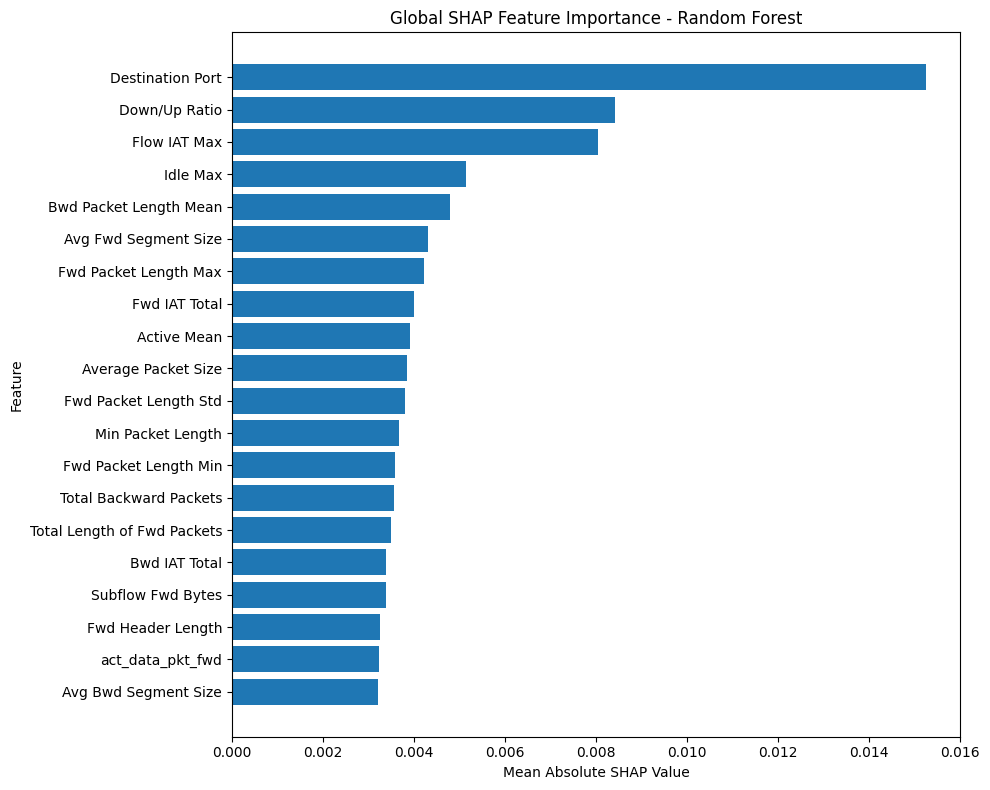


GLOBAL SHAP FEATURE IMPORTANCE ANALYSIS COMPLETED

Features analyzed : 63
Samples analyzed  : 500
Top features shown: 20

Generated artifacts:
✓ global_shap_feature_importance.csv
✓ global_shap_feature_importance.png

Global SHAP analysis is ready for interpretation.


In [4]:
# ============================================================
# STEP 1: Validate SHAP inputs
# ============================================================

import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

print("=" * 60)
print("GLOBAL SHAP FEATURE IMPORTANCE ANALYSIS")
print("=" * 60)

# ------------------------------------------------------------
# Validate required objects from Environment Setup
# ------------------------------------------------------------

required_objects = {
    "model": model,
    "X_test": X_test,
    "feature_names": feature_names
}

print("\nValidating SHAP analysis environment...")

for name, obj in required_objects.items():
    if obj is None:
        raise RuntimeError(f"Required object '{name}' is not available.")

    print(f"✓ {name}")

print("\nSHAP input validation completed.")


# ============================================================
# STEP 2: Prepare SHAP sample
# ============================================================

# Use a controlled sample size for the first complete analysis.
# This avoids unnecessarily expensive SHAP computation while
# preserving enough observations for global feature importance.

SHAP_SAMPLE_SIZE = 500

available_samples = len(X_test)
sample_size = min(SHAP_SAMPLE_SIZE, available_samples)

print("\n" + "=" * 60)
print("SHAP SAMPLE CONFIGURATION")
print("=" * 60)

print(f"\nAvailable test samples : {available_samples:,}")
print(f"Samples selected      : {sample_size:,}")
print(f"Number of features    : {len(feature_names)}")

# Reproducible sampling
rng = np.random.default_rng(42)

sample_indices = rng.choice(
    available_samples,
    size=sample_size,
    replace=False
)

X_shap = X_test[sample_indices]

print("\n✓ SHAP sample prepared")
print(f"SHAP input shape: {X_shap.shape}")


# ============================================================
# STEP 3: Create SHAP TreeExplainer
# ============================================================

print("\n" + "=" * 60)
print("CREATING SHAP TREEEXPLAINER")
print("=" * 60)

start_time = time.time()

explainer = shap.TreeExplainer(model)

explainer_time = time.time() - start_time

print(f"\n✓ TreeExplainer created successfully")
print(f"Explainer creation time: {explainer_time:.2f} seconds")


# ============================================================
# STEP 4: Calculate SHAP values
# ============================================================

print("\n" + "=" * 60)
print("CALCULATING SHAP VALUES")
print("=" * 60)

start_time = time.time()

shap_values = explainer.shap_values(X_shap)

calculation_time = time.time() - start_time

print(f"\n✓ SHAP values calculated successfully")
print(f"Calculation time: {calculation_time:.2f} seconds")

print("\nSHAP output type:")
print(type(shap_values))


# ============================================================
# STEP 5: Inspect SHAP output structure
# ============================================================

print("\n" + "=" * 60)
print("SHAP OUTPUT VALIDATION")
print("=" * 60)

if isinstance(shap_values, list):

    print("\nSHAP output format: List")
    print(f"Number of class outputs: {len(shap_values)}")

    for i, class_values in enumerate(shap_values):
        print(
            f"Class {i}: "
            f"shape = {np.asarray(class_values).shape}"
        )

    # Convert multiclass list:
    # (classes, samples, features)
    # → (samples, features, classes)

    shap_array = np.stack(
        [np.asarray(values) for values in shap_values],
        axis=-1
    )

else:

    shap_array = np.asarray(shap_values)

    print(f"\nSHAP array shape: {shap_array.shape}")


print(f"\nNormalized SHAP array shape: {shap_array.shape}")


# ============================================================
# STEP 6: Calculate global feature importance
# ============================================================

print("\n" + "=" * 60)
print("CALCULATING GLOBAL FEATURE IMPORTANCE")
print("=" * 60)

# For multiclass classification:
#
# SHAP shape:
# (samples, features, classes)
#
# Take absolute SHAP values, average across samples
# and then average across classes.

if shap_array.ndim == 3:

    global_importance = np.mean(
        np.abs(shap_array),
        axis=(0, 2)
    )

elif shap_array.ndim == 2:

    global_importance = np.mean(
        np.abs(shap_array),
        axis=0
    )

else:

    raise ValueError(
        f"Unexpected SHAP output dimensions: {shap_array.ndim}"
    )


# Validate feature count

if len(global_importance) != len(feature_names):

    raise ValueError(
        f"Feature count mismatch: "
        f"{len(global_importance)} SHAP values vs "
        f"{len(feature_names)} feature names."
    )


# ============================================================
# STEP 7: Create feature importance DataFrame
# ============================================================

shap_importance_df = pd.DataFrame({
    "feature": feature_names,
    "mean_absolute_shap_value": global_importance
})

shap_importance_df = (
    shap_importance_df
    .sort_values(
        "mean_absolute_shap_value",
        ascending=False
    )
    .reset_index(drop=True)
)

shap_importance_df["rank"] = (
    shap_importance_df.index + 1
)

# Reorder columns

shap_importance_df = shap_importance_df[
    [
        "rank",
        "feature",
        "mean_absolute_shap_value"
    ]
]


# ============================================================
# STEP 8: Display top features
# ============================================================

TOP_N = 20

print("\n" + "=" * 60)
print(f"TOP {TOP_N} FEATURES BY GLOBAL SHAP IMPORTANCE")
print("=" * 60)

display(
    shap_importance_df.head(TOP_N)
)


# ============================================================
# STEP 9: Save global SHAP importance CSV
# ============================================================

os.makedirs(SHAP_OUTPUT_PATH, exist_ok=True)

shap_importance_csv = os.path.join(
    SHAP_OUTPUT_PATH,
    "global_shap_feature_importance.csv"
)

shap_importance_df.to_csv(
    shap_importance_csv,
    index=False
)

print("\n✓ Global SHAP importance saved:")
print(shap_importance_csv)


# ============================================================
# STEP 10: Generate visualization
# ============================================================

print("\n" + "=" * 60)
print("GENERATING GLOBAL SHAP FEATURE IMPORTANCE PLOT")
print("=" * 60)

plot_data = (
    shap_importance_df
    .head(TOP_N)
    .sort_values(
        "mean_absolute_shap_value",
        ascending=True
    )
)

plt.figure(figsize=(10, 8))

plt.barh(
    plot_data["feature"],
    plot_data["mean_absolute_shap_value"]
)

plt.xlabel("Mean Absolute SHAP Value")
plt.ylabel("Feature")
plt.title(
    "Global SHAP Feature Importance - Random Forest"
)

plt.tight_layout()

shap_importance_plot = os.path.join(
    SHAP_OUTPUT_PATH,
    "global_shap_feature_importance.png"
)

plt.savefig(
    shap_importance_plot,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# STEP 11: Completion summary
# ============================================================

print("\n" + "=" * 60)
print("GLOBAL SHAP FEATURE IMPORTANCE ANALYSIS COMPLETED")
print("=" * 60)

print(f"\nFeatures analyzed : {len(feature_names)}")
print(f"Samples analyzed  : {sample_size:,}")
print(f"Top features shown: {TOP_N}")

print("\nGenerated artifacts:")
print("✓ global_shap_feature_importance.csv")
print("✓ global_shap_feature_importance.png")

print("\nGlobal SHAP analysis is ready for interpretation.")
print("=" * 60)

In [8]:
# Create the variable expected by the subsequent SHAP analysis cells
shap_values_normalized = shap_array

print("shap_values_normalized created successfully")
print(f"Shape: {shap_values_normalized.shape}")

shap_values_normalized created successfully
Shape: (500, 63, 15)


## 6.4 Class-Wise SHAP Feature Importance

Global SHAP feature importance provides an overall ranking of features across all prediction classes. However, different network attack categories may depend on different traffic characteristics.

This section performs class-wise SHAP analysis to identify the most influential features for each target class. The mean absolute SHAP value is calculated independently for every feature and every class.

The analysis provides:

- Class-wise feature importance rankings
- Identification of the most influential features for each attack class
- A consolidated CSV artifact for further research and reporting
- Visualization of the most important features across prediction classes

The previously calculated SHAP values from Section 6.3 are reused to avoid repeating the computationally expensive SHAP calculation.

In [5]:
# ============================================================
# STEP 1: Class-Wise SHAP Feature Importance Analysis
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("=" * 70)
print("CLASS-WISE SHAP FEATURE IMPORTANCE ANALYSIS")
print("=" * 70)


# ------------------------------------------------------------
# Step 1.1: Validate previously calculated SHAP values
# ------------------------------------------------------------

print("\nValidating existing SHAP results...")

required_objects = ["shap_values", "feature_names"]

missing_objects = [
    obj for obj in required_objects
    if obj not in globals()
]

if missing_objects:
    raise RuntimeError(
        f"Required objects are missing: {missing_objects}\n"
        "Please run the SHAP calculation cell from Section 6.3 first."
    )

print("✓ SHAP values available")
print("✓ Feature names available")


# ------------------------------------------------------------
# Step 1.2: Inspect SHAP array
# ------------------------------------------------------------

print("\nSHAP data configuration")
print("-" * 70)

print(f"SHAP array type    : {type(shap_values)}")
print(f"SHAP array shape   : {shap_values.shape}")
print(f"Number of features: {len(feature_names)}")


# Expected shape:
# (samples, features, classes)

if len(shap_values.shape) != 3:
    raise ValueError(
        f"Expected a 3-dimensional SHAP array "
        f"(samples, features, classes), got {shap_values.shape}"
    )

n_samples, n_features, n_classes = shap_values.shape

if n_features != len(feature_names):
    raise ValueError(
        f"Feature mismatch: SHAP contains {n_features} features, "
        f"but feature_names contains {len(feature_names)} names."
    )

print(f"Number of samples : {n_samples}")
print(f"Number of classes : {n_classes}")

print("\n✓ SHAP array validated")


# ------------------------------------------------------------
# Step 1.3: Calculate class-wise mean absolute SHAP values
# ------------------------------------------------------------

print("\nCalculating class-wise feature importance...")
print("-" * 70)

# Mean absolute SHAP value across samples
#
# Result:
# (features, classes)

classwise_importance = np.mean(
    np.abs(shap_values),
    axis=0
)

print(
    f"Class-wise importance matrix shape: "
    f"{classwise_importance.shape}"
)


# ------------------------------------------------------------
# Step 1.4: Retrieve class labels
# ------------------------------------------------------------

# Prefer the model's class labels when available.
if hasattr(model, "classes_"):
    class_labels = np.asarray(model.classes_)
else:
    class_labels = np.arange(n_classes)

if len(class_labels) != n_classes:
    raise ValueError(
        f"Class label mismatch: SHAP contains {n_classes} classes "
        f"but {len(class_labels)} class labels were found."
    )

print(f"Class labels: {class_labels}")


# ------------------------------------------------------------
# Step 1.5: Build consolidated class-wise DataFrame
# ------------------------------------------------------------

classwise_rows = []

for class_index, class_label in enumerate(class_labels):

    importance_values = classwise_importance[:, class_index]

    ranking = np.argsort(
        importance_values
    )[::-1]

    for rank, feature_index in enumerate(ranking, start=1):

        classwise_rows.append({
            "class_index": class_index,
            "class_label": class_label,
            "rank": rank,
            "feature": feature_names[feature_index],
            "mean_absolute_shap_value":
                importance_values[feature_index]
        })


classwise_df = pd.DataFrame(classwise_rows)


# ------------------------------------------------------------
# Step 1.6: Display top features for every class
# ------------------------------------------------------------

TOP_N_CLASSWISE = 10

print("\n" + "=" * 70)
print(f"TOP {TOP_N_CLASSWISE} FEATURES FOR EACH CLASS")
print("=" * 70)

for class_label in class_labels:

    class_data = classwise_df[
        classwise_df["class_label"] == class_label
    ].head(TOP_N_CLASSWISE)

    print(f"\nClass {class_label}")
    print("-" * 50)

    print(
        class_data[
            [
                "rank",
                "feature",
                "mean_absolute_shap_value"
            ]
        ].to_string(index=False)
    )


# ------------------------------------------------------------
# Step 1.7: Save class-wise SHAP results
# ------------------------------------------------------------

classwise_output_path = os.path.join(
    SHAP_OUTPUT_PATH,
    "classwise_shap_feature_importance.csv"
)

classwise_df.to_csv(
    classwise_output_path,
    index=False
)

print("\n" + "=" * 70)
print("CLASS-WISE SHAP RESULTS SAVED")
print("=" * 70)

print(f"\n✓ Output file:")
print(classwise_output_path)

CLASS-WISE SHAP FEATURE IMPORTANCE ANALYSIS

Validating existing SHAP results...
✓ SHAP values available
✓ Feature names available

SHAP data configuration
----------------------------------------------------------------------
SHAP array type    : <class 'numpy.ndarray'>
SHAP array shape   : (500, 63, 15)
Number of features: 63
Number of samples : 500
Number of classes : 15

✓ SHAP array validated

Calculating class-wise feature importance...
----------------------------------------------------------------------
Class-wise importance matrix shape: (63, 15)
Class labels: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14]

TOP 10 FEATURES FOR EACH CLASS

Class 0
--------------------------------------------------
 rank                feature  mean_absolute_shap_value
    1       Destination Port                  0.085391
    2           Flow IAT Max                  0.036523
    3          Down/Up Ratio                  0.031114
    4               Idle Max                  0.029819
    5  Fw

## 6.5 Class-Wise SHAP Importance Visualization

The class-wise SHAP analysis provides numerical feature importance rankings for each prediction class. This section visualizes these results to enable direct comparison of feature importance patterns across classes.

A heatmap is generated using the top globally relevant features and their mean absolute SHAP values across all classes.

The visualization helps identify:

- Features that consistently influence multiple classes
- Features that are particularly important for specific classes
- Differences in feature importance between prediction classes
- Class-specific patterns that may be useful for interpreting network attack behaviour

The visualization is generated from the class-wise SHAP results calculated in Section 6.4. No additional SHAP value calculation is performed.

CLASS-WISE SHAP IMPORTANCE VISUALIZATION

Validating class-wise SHAP results...
✓ Class-wise SHAP DataFrame available
✓ Class-wise importance matrix available
✓ Feature names available
✓ Class labels available

Selecting features for visualization...
----------------------------------------------------------------------
Top features selected: 20
 1. Destination Port
 2. Down/Up Ratio
 3. Flow IAT Max
 4. Idle Max
 5. Bwd Packet Length Mean
 6. Avg Fwd Segment Size
 7. Fwd Packet Length Max
 8. Fwd IAT Total
 9. Active Mean
10. Average Packet Size
11. Fwd Packet Length Std
12. Min Packet Length
13. Fwd Packet Length Min
14. Total Backward Packets
15. Total Length of Fwd Packets
16. Bwd IAT Total
17. Subflow Fwd Bytes
18. Fwd Header Length
19. act_data_pkt_fwd
20. Avg Bwd Segment Size

Heatmap matrix shape: (20, 15)

Generating class-wise SHAP heatmap...
----------------------------------------------------------------------


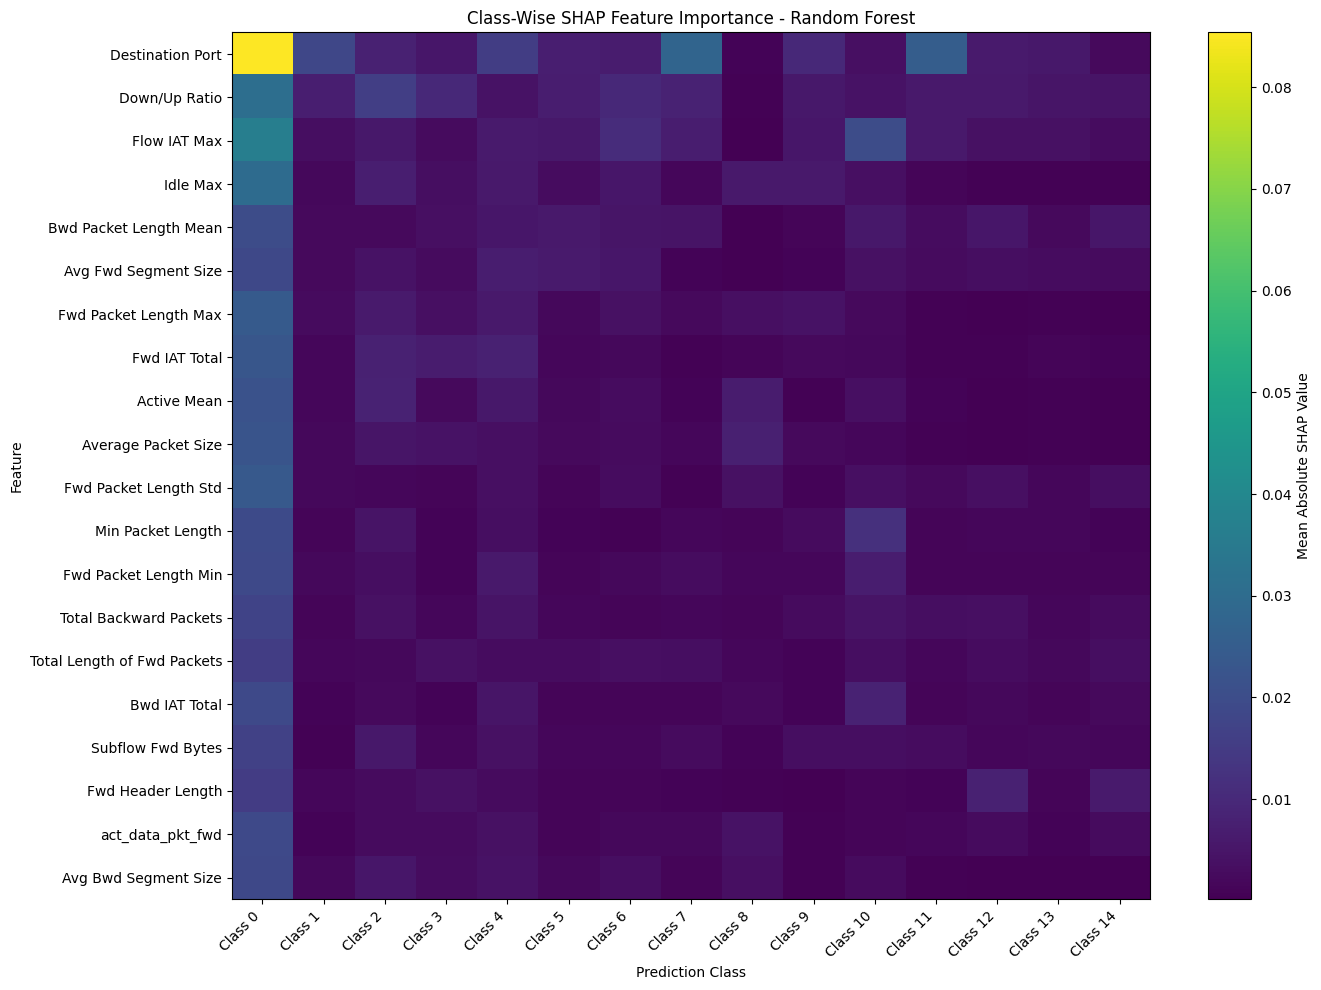


CLASS-WISE SHAP VISUALIZATION COMPLETED

Features visualized : 20
Classes visualized  : 15

Generated artifacts:
✓ classwise_shap_feature_importance_heatmap.png
✓ classwise_shap_heatmap_data.csv

Heatmap saved to:
/content/drive/MyDrive/AI-Network-Intrusion-Detection-System/outputs/shap/classwise_shap_feature_importance_heatmap.png

Class-wise SHAP visualization is ready for interpretation.


In [6]:
# ============================================================
# STEP 1: Class-Wise SHAP Heatmap Visualization
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("=" * 70)
print("CLASS-WISE SHAP IMPORTANCE VISUALIZATION")
print("=" * 70)


# ------------------------------------------------------------
# Step 1.1: Validate class-wise SHAP results
# ------------------------------------------------------------

print("\nValidating class-wise SHAP results...")

required_objects = [
    "classwise_df",
    "classwise_importance",
    "feature_names",
    "class_labels"
]

missing_objects = [
    obj for obj in required_objects
    if obj not in globals()
]

if missing_objects:
    raise RuntimeError(
        f"Required objects are missing: {missing_objects}\n"
        "Please run Section 6.4 first."
    )

print("✓ Class-wise SHAP DataFrame available")
print("✓ Class-wise importance matrix available")
print("✓ Feature names available")
print("✓ Class labels available")


# ------------------------------------------------------------
# Step 1.2: Identify the most important features globally
# ------------------------------------------------------------

print("\nSelecting features for visualization...")
print("-" * 70)

# Calculate overall mean absolute importance across classes
overall_feature_importance = np.mean(
    classwise_importance,
    axis=1
)

global_feature_ranking = np.argsort(
    overall_feature_importance
)[::-1]


# Display top features in the heatmap
TOP_HEATMAP_FEATURES = 20

selected_feature_indices = global_feature_ranking[
    :TOP_HEATMAP_FEATURES
]

selected_features = [
    feature_names[i]
    for i in selected_feature_indices
]

print(f"Top features selected: {TOP_HEATMAP_FEATURES}")

for rank, feature in enumerate(
    selected_features,
    start=1
):
    print(f"{rank:2d}. {feature}")


# ------------------------------------------------------------
# Step 1.3: Create heatmap matrix
# ------------------------------------------------------------

heatmap_data = classwise_importance[
    selected_feature_indices,
    :
]

heatmap_df = pd.DataFrame(
    heatmap_data,
    index=selected_features,
    columns=[
        f"Class {label}"
        for label in class_labels
    ]
)

print(
    f"\nHeatmap matrix shape: "
    f"{heatmap_df.shape}"
)


# ------------------------------------------------------------
# Step 1.4: Generate visualization
# ------------------------------------------------------------

print("\nGenerating class-wise SHAP heatmap...")
print("-" * 70)

plt.figure(
    figsize=(14, 10)
)

plt.imshow(
    heatmap_df.values,
    aspect="auto",
    interpolation="nearest"
)

plt.colorbar(
    label="Mean Absolute SHAP Value"
)

plt.xticks(
    ticks=np.arange(len(class_labels)),
    labels=[
        f"Class {label}"
        for label in class_labels
    ],
    rotation=45,
    ha="right"
)

plt.yticks(
    ticks=np.arange(len(selected_features)),
    labels=selected_features
)

plt.xlabel("Prediction Class")
plt.ylabel("Feature")

plt.title(
    "Class-Wise SHAP Feature Importance - Random Forest"
)

plt.tight_layout()


# ------------------------------------------------------------
# Step 1.5: Save visualization
# ------------------------------------------------------------

classwise_heatmap_path = os.path.join(
    SHAP_OUTPUT_PATH,
    "classwise_shap_feature_importance_heatmap.png"
)

plt.savefig(
    classwise_heatmap_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# Step 1.6: Save heatmap data
# ------------------------------------------------------------

classwise_heatmap_csv = os.path.join(
    SHAP_OUTPUT_PATH,
    "classwise_shap_heatmap_data.csv"
)

heatmap_df.to_csv(
    classwise_heatmap_csv
)


# ------------------------------------------------------------
# Step 1.7: Completion summary
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("CLASS-WISE SHAP VISUALIZATION COMPLETED")
print("=" * 70)

print(f"\nFeatures visualized : {len(selected_features)}")
print(f"Classes visualized  : {len(class_labels)}")

print("\nGenerated artifacts:")
print("✓ classwise_shap_feature_importance_heatmap.png")
print("✓ classwise_shap_heatmap_data.csv")

print("\nHeatmap saved to:")
print(classwise_heatmap_path)

print("\nClass-wise SHAP visualization is ready for interpretation.")

## 6.6 SHAP Dependence Analysis

SHAP dependence analysis is used to study how individual feature values influence model predictions.

The analysis visualizes the relationship between feature values and their corresponding SHAP contributions for the most important features identified by the global SHAP analysis.

This helps interpret how changes in important network traffic features affect the Random Forest model's predictions.

SHAP DEPENDENCE ANALYSIS

Validating SHAP dependence analysis environment...
✓ X_shap available
✓ feature_names available
✓ normalized SHAP values available

Input shapes:
X_shap shape              : (500, 63)
SHAP values shape         : (500, 63, 15)
Number of feature names  : 63

Top features selected for dependence analysis:
1. Destination Port (mean |SHAP| = 0.015238)
2. Down/Up Ratio (mean |SHAP| = 0.008418)
3. Flow IAT Max (mean |SHAP| = 0.008054)
4. Idle Max (mean |SHAP| = 0.005140)
5. Bwd Packet Length Mean (mean |SHAP| = 0.004795)

Generating SHAP dependence plots...


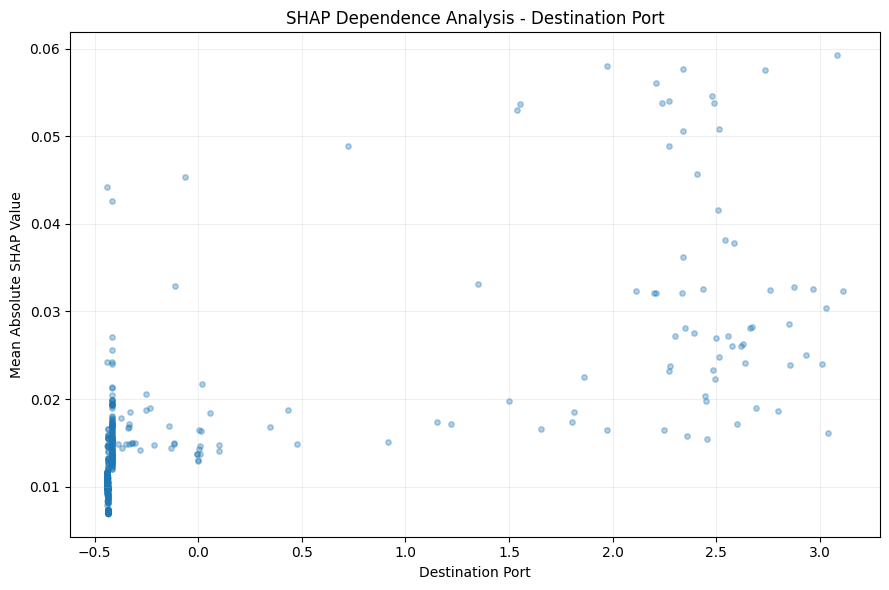

✓ Saved: /content/drive/MyDrive/AI-Network-Intrusion-Detection-System/outputs/shap/shap_dependence_Destination_Port.png


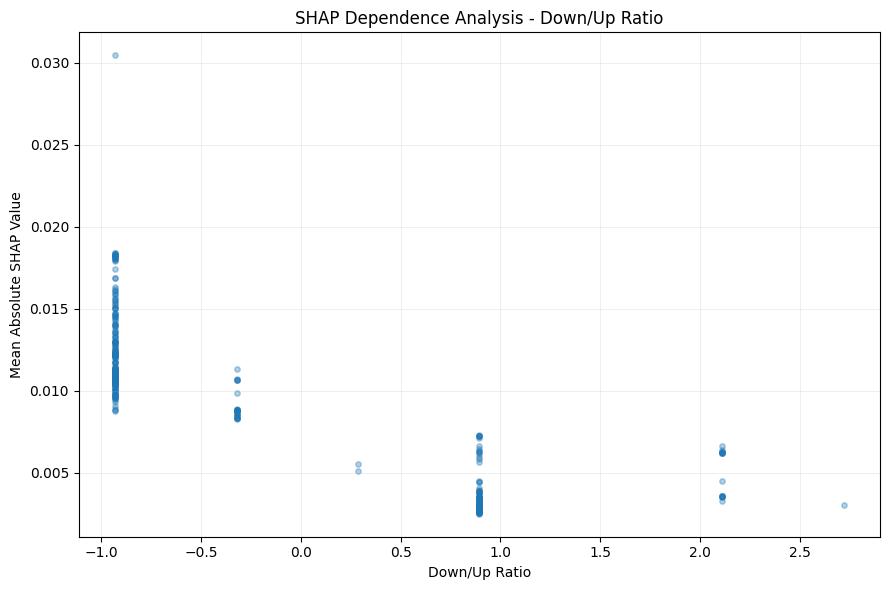

✓ Saved: /content/drive/MyDrive/AI-Network-Intrusion-Detection-System/outputs/shap/shap_dependence_Down_Up_Ratio.png


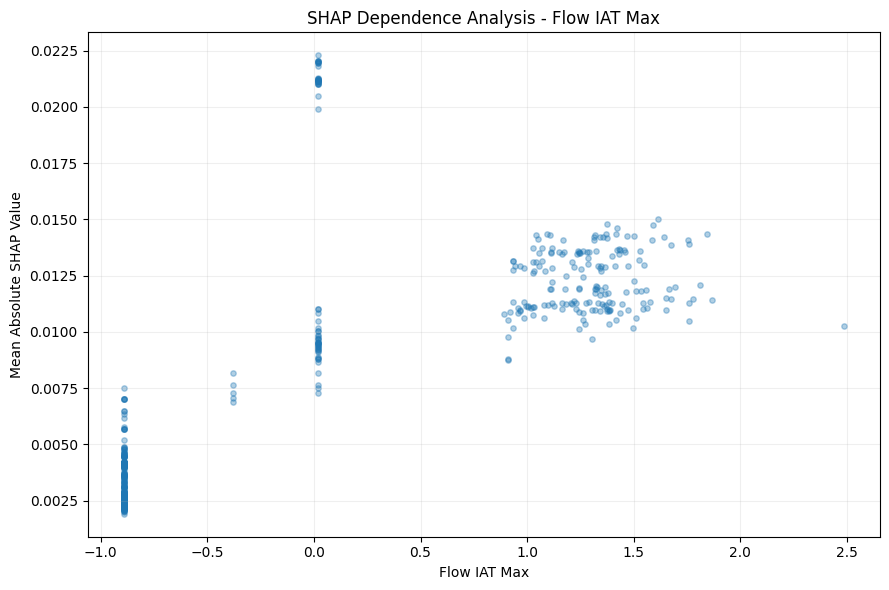

✓ Saved: /content/drive/MyDrive/AI-Network-Intrusion-Detection-System/outputs/shap/shap_dependence_Flow_IAT_Max.png


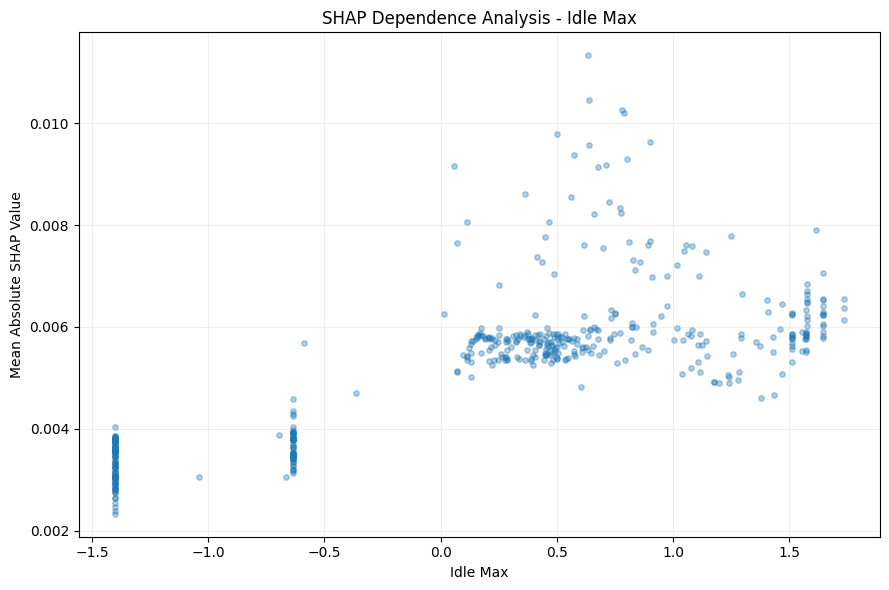

✓ Saved: /content/drive/MyDrive/AI-Network-Intrusion-Detection-System/outputs/shap/shap_dependence_Idle_Max.png


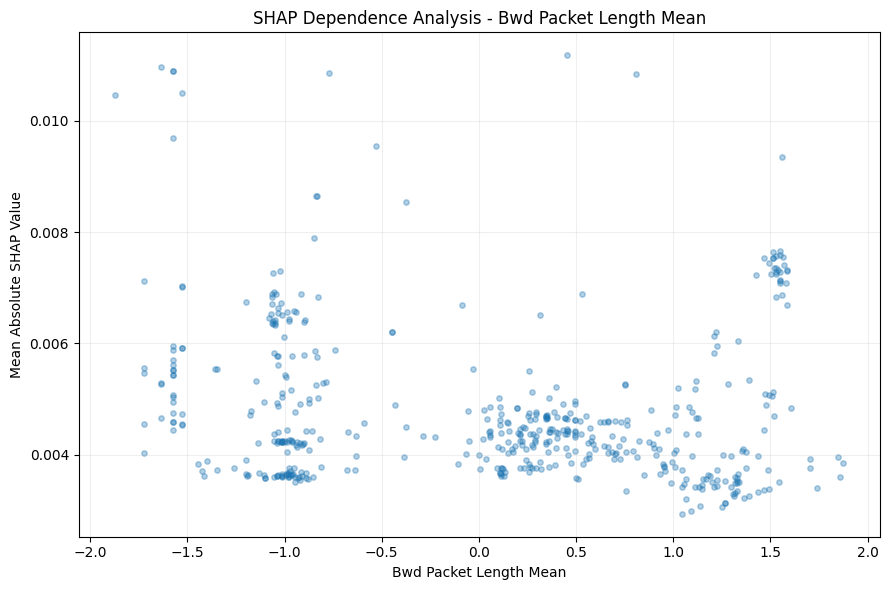

✓ Saved: /content/drive/MyDrive/AI-Network-Intrusion-Detection-System/outputs/shap/shap_dependence_Bwd_Packet_Length_Mean.png

✓ Dependence data saved:
/content/drive/MyDrive/AI-Network-Intrusion-Detection-System/outputs/shap/shap_dependence_data.csv

SHAP DEPENDENCE ANALYSIS COMPLETED

Features analyzed : 5
Samples analyzed  : 500
Classes included  : 15

Features analyzed:
1. Destination Port
2. Down/Up Ratio
3. Flow IAT Max
4. Idle Max
5. Bwd Packet Length Mean

Generated artifacts:
✓ shap_dependence_<feature>.png
✓ shap_dependence_data.csv

SHAP dependence analysis is ready for interpretation.


In [9]:
# ============================================================
# 6.6 SHAP DEPENDENCE ANALYSIS
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("=" * 70)
print("SHAP DEPENDENCE ANALYSIS")
print("=" * 70)

# ------------------------------------------------------------
# Step 1: Validate required objects
# ------------------------------------------------------------

print("\nValidating SHAP dependence analysis environment...")

required_objects = [
    "X_shap",
    "feature_names",
    "shap_values_normalized"
]

missing_objects = [
    obj for obj in required_objects
    if obj not in globals()
]

if missing_objects:
    raise RuntimeError(
        f"Required objects are missing: {missing_objects}\n"
        "Please make sure the previous SHAP cells have been executed."
    )

print("✓ X_shap available")
print("✓ feature_names available")
print("✓ normalized SHAP values available")


# ------------------------------------------------------------
# Step 2: Validate shapes
# ------------------------------------------------------------

X_shap_array = np.asarray(X_shap)
shap_array = np.asarray(shap_values_normalized)

print("\nInput shapes:")
print(f"X_shap shape              : {X_shap_array.shape}")
print(f"SHAP values shape         : {shap_array.shape}")
print(f"Number of feature names  : {len(feature_names)}")

if X_shap_array.ndim != 2:
    raise ValueError("X_shap must be a 2-dimensional feature matrix.")

if shap_array.ndim != 3:
    raise ValueError(
        "Expected multiclass SHAP values with shape "
        "(samples, features, classes)."
    )

if X_shap_array.shape[1] != shap_array.shape[1]:
    raise ValueError(
        "Number of features in X_shap and SHAP values do not match."
    )


# ------------------------------------------------------------
# Step 3: Calculate global importance ranking
# ------------------------------------------------------------

# Mean absolute SHAP across samples AND classes
global_importance = np.mean(
    np.abs(shap_array),
    axis=(0, 2)
)

importance_df = pd.DataFrame({
    "feature": feature_names,
    "mean_absolute_shap": global_importance
})

importance_df = importance_df.sort_values(
    "mean_absolute_shap",
    ascending=False
).reset_index(drop=True)

# Select top features for dependence analysis
TOP_DEPENDENCE_FEATURES = 5

top_features = importance_df.head(
    TOP_DEPENDENCE_FEATURES
)["feature"].tolist()

print("\nTop features selected for dependence analysis:")

for i, feature in enumerate(top_features, 1):
    importance = importance_df.loc[
        importance_df["feature"] == feature,
        "mean_absolute_shap"
    ].iloc[0]

    print(f"{i}. {feature} "
          f"(mean |SHAP| = {importance:.6f})")


# ------------------------------------------------------------
# Step 4: Create output directory
# ------------------------------------------------------------

if "SHAP_OUTPUT_PATH" not in globals():
    SHAP_OUTPUT_PATH = "/content/drive/MyDrive/AI-Network-Intrusion-Detection-System/outputs/shap"

os.makedirs(SHAP_OUTPUT_PATH, exist_ok=True)


# ------------------------------------------------------------
# Step 5: Generate dependence plots
# ------------------------------------------------------------

print("\nGenerating SHAP dependence plots...")

dependence_data = []

for feature in top_features:

    feature_index = list(feature_names).index(feature)

    # Feature values
    feature_values = X_shap_array[:, feature_index]

    # Mean absolute SHAP contribution across all classes
    feature_shap = np.mean(
        np.abs(shap_array[:, feature_index, :]),
        axis=1
    )

    # Store data for CSV
    temp_df = pd.DataFrame({
        "feature": feature,
        "feature_value": feature_values,
        "mean_absolute_shap": feature_shap
    })

    dependence_data.append(temp_df)

    # --------------------------------------------------------
    # Plot
    # --------------------------------------------------------

    plt.figure(figsize=(9, 6))

    plt.scatter(
        feature_values,
        feature_shap,
        alpha=0.35,
        s=15
    )

    plt.xlabel(feature)
    plt.ylabel("Mean Absolute SHAP Value")
    plt.title(
        f"SHAP Dependence Analysis - {feature}"
    )

    plt.grid(
        True,
        alpha=0.2
    )

    plt.tight_layout()

    # Safe filename
    safe_feature_name = (
        str(feature)
        .replace("/", "_")
        .replace("\\", "_")
        .replace(" ", "_")
    )

    plot_path = os.path.join(
        SHAP_OUTPUT_PATH,
        f"shap_dependence_{safe_feature_name}.png"
    )

    plt.savefig(
        plot_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    print(f"✓ Saved: {plot_path}")


# ------------------------------------------------------------
# Step 6: Save dependence data
# ------------------------------------------------------------

dependence_df = pd.concat(
    dependence_data,
    ignore_index=True
)

dependence_csv_path = os.path.join(
    SHAP_OUTPUT_PATH,
    "shap_dependence_data.csv"
)

dependence_df.to_csv(
    dependence_csv_path,
    index=False
)

print("\n✓ Dependence data saved:")
print(dependence_csv_path)


# ------------------------------------------------------------
# Step 7: Completion summary
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("SHAP DEPENDENCE ANALYSIS COMPLETED")
print("=" * 70)

print(f"\nFeatures analyzed : {len(top_features)}")
print(f"Samples analyzed  : {X_shap_array.shape[0]}")
print(f"Classes included  : {shap_array.shape[2]}")

print("\nFeatures analyzed:")

for i, feature in enumerate(top_features, 1):
    print(f"{i}. {feature}")

print("\nGenerated artifacts:")
print("✓ shap_dependence_<feature>.png")
print("✓ shap_dependence_data.csv")

print("\nSHAP dependence analysis is ready for interpretation.")

## 6.7 Local SHAP Prediction Explanations

Global SHAP analysis explains the overall behaviour of the Random Forest model, while local SHAP analysis explains why the model produced a particular prediction for an individual network-flow sample.

This section generates local explanations for representative intrusion predictions using the SHAP values already calculated in the previous sections.

For each selected prediction, the analysis identifies:

- The predicted intrusion class
- The actual class, when available
- The most influential features for that prediction
- The signed SHAP contribution of each important feature
- The input value associated with each feature

Positive SHAP values indicate that a feature contributes toward the selected prediction class, while negative SHAP values indicate a contribution away from that class.

The resulting local explanation data and visualizations are persisted for downstream dashboard integration.

LOCAL SHAP PREDICTION EXPLANATIONS

Validating local SHAP analysis environment...
✓ Random Forest model available
✓ SHAP input samples available
✓ SHAP values available
✓ Feature names available

Input dimensions:
X_shap shape    : (500, 63)
SHAP shape      : (500, 63, 15)
Feature count   : 63

✓ SHAP dimensions validated

Model classes:
[ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14]

✓ 15 prediction classes validated

Generating Random Forest predictions...
✓ Predictions generated
Prediction count: 500

Representative samples selected:
✓ Sample 0 → predicted class: 0
✓ Sample 108 → predicted class: 2
✓ Sample 5 → predicted class: 3
✓ Sample 1 → predicted class: 4
✓ Sample 269 → predicted class: 6

Local explanation output directory:
/content/drive/MyDrive/AI-Network-Intrusion-Detection-System/outputs/shap/local_explanations

----------------------------------------------------------------------
LOCAL EXPLANATION - SAMPLE 0
--------------------------------------------------------------

,sample_index,predicted_class,actual_class,predicted_class_index,rank,feature,feature_value,shap_value,absolute_shap_value
0,0,0,0,0,1,Destination Port,-0.417274,0.100722,0.100722
1,0,0,0,0,2,Idle Max,0.789030,0.074667,0.074667
2,0,0,0,0,3,Fwd Packet Length Max,0.789030,0.047682,0.047682
3,0,0,0,0,4,Down/Up Ratio,-0.930077,0.041984,0.041984
4,0,0,0,0,5,Avg Bwd Segment Size,1.379086,0.036766,0.036766
5,0,0,0,0,6,Average Packet Size,1.159114,0.034054,0.034054
6,0,0,0,0,7,Fwd IAT Total,1.453907,0.032222,0.032222
7,0,0,0,0,8,Active Mean,1.379086,0.031311,0.031311
8,0,0,0,0,9,Subflow Bwd Bytes,2.461603,0.027077,0.027077
9,0,0,0,0,10,Bwd Packets/s,1.584789,0.022664,0.022664



Generating local SHAP visualizations...


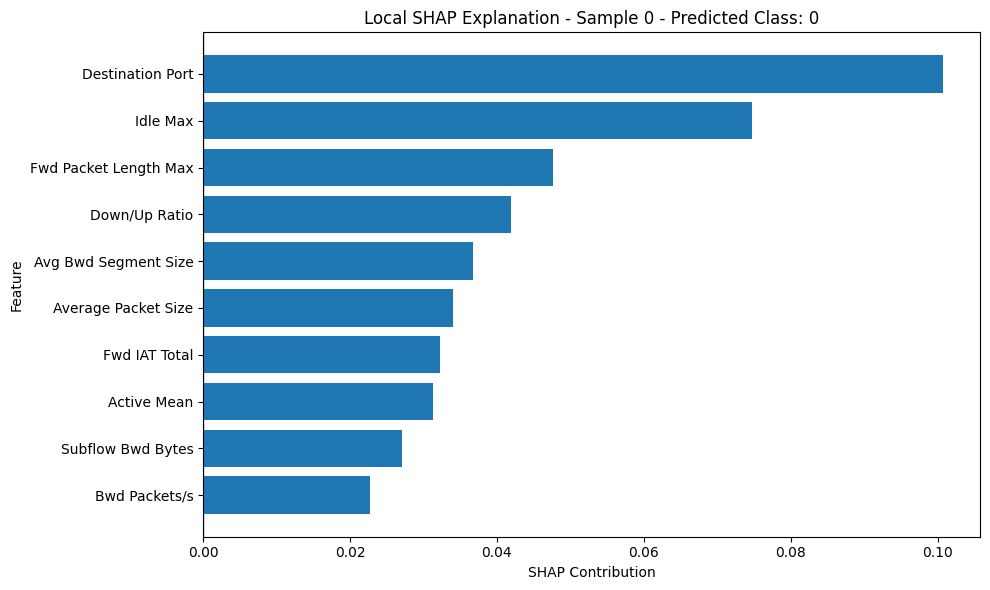

✓ Saved: /content/drive/MyDrive/AI-Network-Intrusion-Detection-System/outputs/shap/local_explanations/local_shap_sample_0.png


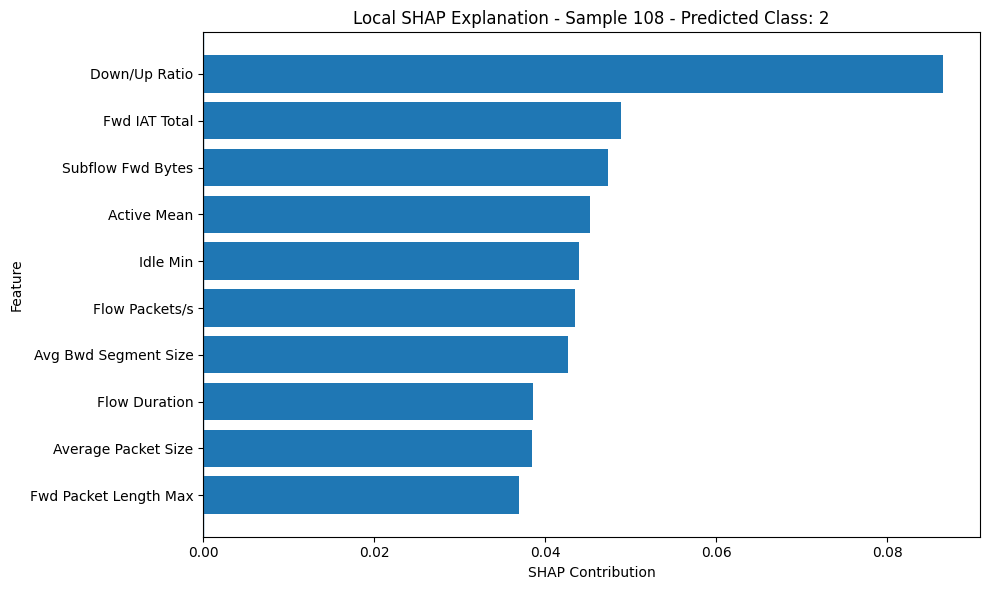

✓ Saved: /content/drive/MyDrive/AI-Network-Intrusion-Detection-System/outputs/shap/local_explanations/local_shap_sample_108.png


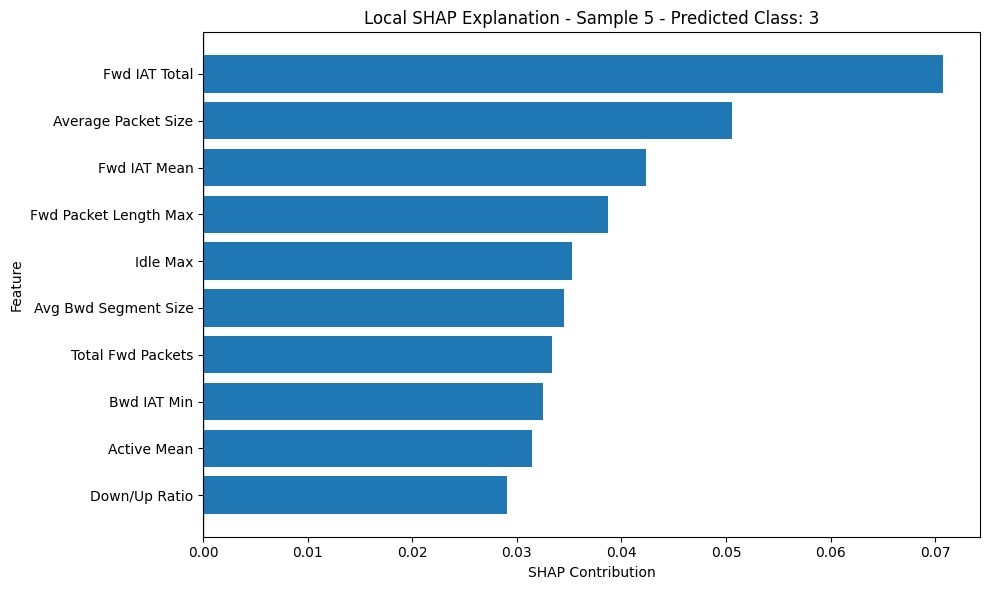

✓ Saved: /content/drive/MyDrive/AI-Network-Intrusion-Detection-System/outputs/shap/local_explanations/local_shap_sample_5.png


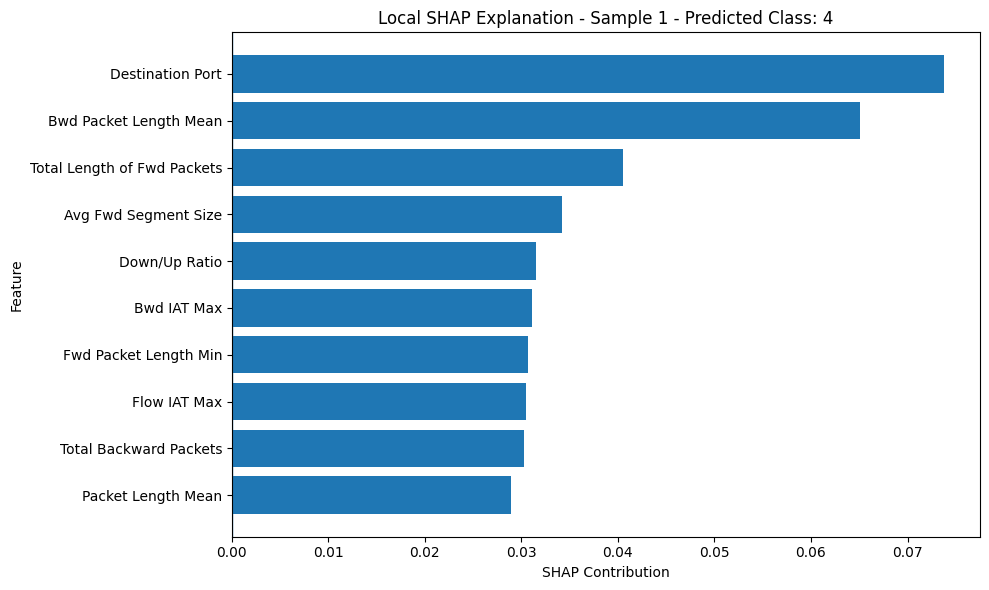

✓ Saved: /content/drive/MyDrive/AI-Network-Intrusion-Detection-System/outputs/shap/local_explanations/local_shap_sample_1.png


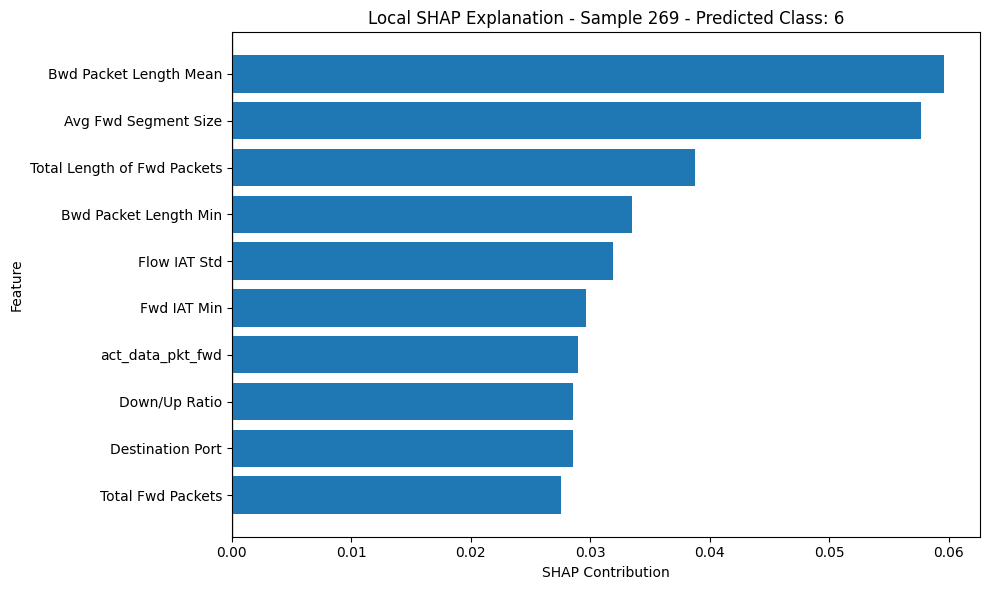

✓ Saved: /content/drive/MyDrive/AI-Network-Intrusion-Detection-System/outputs/shap/local_explanations/local_shap_sample_269.png

✓ Local explanation data saved:
/content/drive/MyDrive/AI-Network-Intrusion-Detection-System/outputs/shap/local_explanations/local_shap_explanations.csv
✓ Local prediction summary saved:
/content/drive/MyDrive/AI-Network-Intrusion-Detection-System/outputs/shap/local_explanations/local_shap_prediction_summary.csv

LOCAL SHAP VALIDATION
✓ Expected number of explanation records generated
✓ All selected samples have local explanations
✓ All explained features are valid model features

LOCAL SHAP PREDICTION EXPLANATIONS COMPLETED

Generated artifacts:
✓ local_shap_explanations.csv
✓ local_shap_prediction_summary.csv
✓ local_shap_sample_<index>.png

Local SHAP explanations are ready for downstream dashboard integration.


In [15]:
# ============================================================
# 6.7 Local SHAP Prediction Explanations
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("=" * 70)
print("LOCAL SHAP PREDICTION EXPLANATIONS")
print("=" * 70)


# ------------------------------------------------------------
# STEP 1: Validate required SHAP objects
# ------------------------------------------------------------

print("\nValidating local SHAP analysis environment...")

required_objects = [
    "model",
    "X_shap",
    "shap_array",
    "feature_names"
]

missing_objects = [
    obj for obj in required_objects
    if obj not in globals()
]

if missing_objects:
    raise RuntimeError(
        f"Required objects are missing: {missing_objects}\n"
        "Please make sure the previous SHAP sections have "
        "been executed successfully."
    )

print("✓ Random Forest model available")
print("✓ SHAP input samples available")
print("✓ SHAP values available")
print("✓ Feature names available")


# ------------------------------------------------------------
# STEP 2: Validate SHAP dimensions
# ------------------------------------------------------------

X_shap_array = np.asarray(X_shap)
shap_array_local = np.asarray(shap_array)

print("\nInput dimensions:")
print(f"X_shap shape    : {X_shap_array.shape}")
print(f"SHAP shape      : {shap_array_local.shape}")
print(f"Feature count   : {len(feature_names)}")


if X_shap_array.ndim != 2:
    raise RuntimeError(
        f"Expected X_shap to be 2-dimensional, "
        f"got shape {X_shap_array.shape}"
    )


if shap_array_local.ndim != 3:
    raise RuntimeError(
        f"Expected multiclass SHAP array with 3 dimensions "
        f"(samples, features, classes), "
        f"got shape {shap_array_local.shape}"
    )


n_samples, n_features, n_classes = shap_array_local.shape


if X_shap_array.shape[0] != n_samples:
    raise RuntimeError(
        f"Sample mismatch: X_shap contains "
        f"{X_shap_array.shape[0]} samples, "
        f"but SHAP contains {n_samples} samples."
    )


if X_shap_array.shape[1] != n_features:
    raise RuntimeError(
        f"Feature mismatch: X_shap contains "
        f"{X_shap_array.shape[1]} features, "
        f"but SHAP contains {n_features} features."
    )


if len(feature_names) != n_features:
    raise RuntimeError(
        f"Feature-name mismatch: "
        f"{len(feature_names)} feature names vs "
        f"{n_features} SHAP features."
    )


print("\n✓ SHAP dimensions validated")


# ------------------------------------------------------------
# STEP 3: Recover model classes
# ------------------------------------------------------------

if not hasattr(model, "classes_"):
    raise RuntimeError(
        "The Random Forest model does not expose classes_. "
        "Unable to map SHAP class indices to prediction labels."
    )


class_labels = np.asarray(model.classes_)


if len(class_labels) != n_classes:
    raise RuntimeError(
        f"Class mismatch: model contains "
        f"{len(class_labels)} classes, "
        f"but SHAP contains {n_classes} class outputs."
    )


print("\nModel classes:")
print(class_labels)

print(f"\n✓ {len(class_labels)} prediction classes validated")


# ------------------------------------------------------------
# STEP 4: Generate predictions for SHAP samples
# ------------------------------------------------------------

print("\nGenerating Random Forest predictions...")

predictions = model.predict(X_shap_array)

print("✓ Predictions generated")
print(f"Prediction count: {len(predictions)}")


# ------------------------------------------------------------
# STEP 5: Select representative predictions
# ------------------------------------------------------------

# Select one deterministic sample for each prediction class.
# This provides representative local explanations without
# recalculating SHAP values.

selected_sample_indices = []

for class_label in class_labels:

    matching_indices = np.where(
        predictions == class_label
    )[0]

    if len(matching_indices) > 0:

        selected_sample_indices.append(
            int(matching_indices[0])
        )


# Limit the number of local explanations for the notebook
# demonstration while ensuring deterministic behaviour.

MAX_LOCAL_EXPLANATIONS = 5

selected_sample_indices = (
    selected_sample_indices[:MAX_LOCAL_EXPLANATIONS]
)


if len(selected_sample_indices) == 0:
    raise RuntimeError(
        "No representative predictions could be selected."
    )


print("\nRepresentative samples selected:")

for sample_idx in selected_sample_indices:

    print(
        f"✓ Sample {sample_idx} "
        f"→ predicted class: "
        f"{predictions[sample_idx]}"
    )


# ------------------------------------------------------------
# STEP 6: Create local explanation output directory
# ------------------------------------------------------------

local_shap_output_dir = os.path.join(
    SHAP_OUTPUT_PATH,
    "local_explanations"
)

os.makedirs(
    local_shap_output_dir,
    exist_ok=True
)

print("\nLocal explanation output directory:")
print(local_shap_output_dir)


# ------------------------------------------------------------
# STEP 7: Generate local SHAP explanations
# ------------------------------------------------------------

TOP_LOCAL_FEATURES = 10

local_explanation_records = []
local_summary_records = []


for sample_idx in selected_sample_indices:

    # --------------------------------------------------------
    # Prediction information
    # --------------------------------------------------------

    predicted_class = predictions[sample_idx]

    actual_class = y_test[
    sample_indices[sample_idx]
               ]

    # Locate the SHAP output corresponding to the
    # predicted class.
    predicted_class_index = np.where(
        class_labels == predicted_class
    )[0]

    if len(predicted_class_index) != 1:
        raise RuntimeError(
            f"Could not uniquely locate SHAP class index "
            f"for prediction '{predicted_class}'."
        )

    predicted_class_index = int(
        predicted_class_index[0]
    )

    # --------------------------------------------------------
    # Extract SHAP values for predicted class
    # --------------------------------------------------------

    sample_shap_values = shap_array_local[
        sample_idx,
        :,
        predicted_class_index
    ]

    sample_features = X_shap_array[
        sample_idx
    ]

    # --------------------------------------------------------
    # Rank features by absolute SHAP contribution
    # --------------------------------------------------------

    ranking_order = np.argsort(
        np.abs(sample_shap_values)
    )[::-1]

    top_indices = ranking_order[
        :TOP_LOCAL_FEATURES
    ]

    print("\n" + "-" * 70)
    print(
        f"LOCAL EXPLANATION - SAMPLE {sample_idx}"
    )
    print("-" * 70)

    print(
        f"Predicted class: {predicted_class}"
    )

    print(
    f"Actual class: {actual_class}"
    )

    print(
        f"SHAP class index: "
        f"{predicted_class_index}"
    )

    print(
        f"\nTop {TOP_LOCAL_FEATURES} contributing features:"
    )

    # --------------------------------------------------------
    # Store local explanation records
    # --------------------------------------------------------

    for rank, feature_idx in enumerate(
        top_indices,
        start=1
    ):

        feature_name = feature_names[
            feature_idx
        ]

        feature_value = sample_features[
            feature_idx
        ]

        shap_contribution = sample_shap_values[
            feature_idx
        ]

        absolute_shap = abs(
            shap_contribution
        )

        print(
            f"{rank:2d}. "
            f"{feature_name} | "
            f"Feature value = {feature_value:.6f} | "
            f"SHAP = {shap_contribution:+.6f}"
        )

        local_explanation_records.append({

            "sample_index":
                int(sample_idx),

            "predicted_class":
                str(predicted_class),

            "actual_class":
                str(actual_class),

            "predicted_class_index":
                int(predicted_class_index),

            "rank":
                int(rank),

            "feature":
                feature_name,

            "feature_value":
                float(feature_value),

            "shap_value":
                float(shap_contribution),

            "absolute_shap_value":
                float(absolute_shap)

        })

    # --------------------------------------------------------
    # Store prediction-level summary
    # --------------------------------------------------------

    local_summary_records.append({

        "sample_index":
            int(sample_idx),

        "predicted_class":
            str(predicted_class),

        "actual_class":
            str(actual_class),

        "prediction_correct":
            bool(predicted_class == actual_class),

        "predicted_class_index":
            int(predicted_class_index),

        "top_feature":
            feature_names[top_indices[0]],

        "top_feature_shap_value":
            float(
                sample_shap_values[top_indices[0]]
            )

    })


# ------------------------------------------------------------
# STEP 8: Create local explanation DataFrames
# ------------------------------------------------------------

local_explanations_df = pd.DataFrame(
    local_explanation_records
)

local_summary_df = pd.DataFrame(
    local_summary_records
)


if local_explanations_df.empty:
    raise RuntimeError(
        "Local SHAP explanation DataFrame is empty."
    )


print("\n" + "=" * 70)
print("LOCAL SHAP EXPLANATIONS GENERATED")
print("=" * 70)

print(
    f"\nSamples explained: "
    f"{len(selected_sample_indices)}"
)

print(
    f"Features per explanation: "
    f"{TOP_LOCAL_FEATURES}"
)

print(
    f"Explanation records: "
    f"{len(local_explanations_df)}"
)


# ------------------------------------------------------------
# STEP 9: Display local explanation results
# ------------------------------------------------------------

print("\nLocal explanation data:")

display(
    local_explanations_df
)


# ------------------------------------------------------------
# STEP 10: Generate local SHAP plots
# ------------------------------------------------------------

print("\nGenerating local SHAP visualizations...")


for sample_idx in selected_sample_indices:

    sample_data = local_explanations_df[
        local_explanations_df["sample_index"]
        == sample_idx
    ].copy()

    # Sort so the largest contribution appears at the top.
    sample_data = sample_data.sort_values(
        "absolute_shap_value",
        ascending=True
    )

    predicted_class = sample_data[
        "predicted_class"
    ].iloc[0]

    plt.figure(
        figsize=(10, 6)
    )

    plt.barh(
        sample_data["feature"],
        sample_data["shap_value"]
    )

    plt.axvline(
        0,
        linewidth=1
    )

    plt.xlabel(
        "SHAP Contribution"
    )

    plt.ylabel(
        "Feature"
    )

    plt.title(
        f"Local SHAP Explanation - "
        f"Sample {sample_idx} - "
        f"Predicted Class: {predicted_class}"
    )

    plt.tight_layout()

    plot_path = os.path.join(
        local_shap_output_dir,
        f"local_shap_sample_{sample_idx}.png"
    )

    plt.savefig(
        plot_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    print(
        f"✓ Saved: {plot_path}"
    )


# ------------------------------------------------------------
# STEP 11: Persist local explanation data
# ------------------------------------------------------------

local_explanations_path = os.path.join(
    local_shap_output_dir,
    "local_shap_explanations.csv"
)

local_summary_path = os.path.join(
    local_shap_output_dir,
    "local_shap_prediction_summary.csv"
)


local_explanations_df.to_csv(
    local_explanations_path,
    index=False
)

local_summary_df.to_csv(
    local_summary_path,
    index=False
)


print("\n✓ Local explanation data saved:")
print(local_explanations_path)

print("✓ Local prediction summary saved:")
print(local_summary_path)


# ------------------------------------------------------------
# STEP 12: Final validation
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("LOCAL SHAP VALIDATION")
print("=" * 70)

if len(local_explanations_df) == (
    len(selected_sample_indices)
    * TOP_LOCAL_FEATURES
):

    print(
        "✓ Expected number of explanation records generated"
    )

else:

    raise RuntimeError(
        "Unexpected number of local SHAP explanation records."
    )


if local_explanations_df[
    "sample_index"
].nunique() == len(
    selected_sample_indices
):

    print(
        "✓ All selected samples have local explanations"
    )

else:

    raise RuntimeError(
        "Some selected samples are missing local explanations."
    )


if local_explanations_df[
    "feature"
].isin(
    feature_names
).all():

    print(
        "✓ All explained features are valid model features"
    )

else:

    raise RuntimeError(
        "Invalid feature name detected in local explanations."
    )


print("\n" + "=" * 70)
print("LOCAL SHAP PREDICTION EXPLANATIONS COMPLETED")
print("=" * 70)

print(
    "\nGenerated artifacts:"
)

print(
    "✓ local_shap_explanations.csv"
)

print(
    "✓ local_shap_prediction_summary.csv"
)

print(
    "✓ local_shap_sample_<index>.png"
)

print(
    "\nLocal SHAP explanations are ready for "
    "downstream dashboard integration."
)

## 6.8 SHAP Artifact Persistence

This section persists the validated SHAP explanation artifacts generated in the previous analyses.

The artifacts are stored in a structured format for downstream dashboard integration and reproducible explainability handoff.

The trained Random Forest model is treated as a read-only artifact and is not modified or retrained.

In [19]:
# ============================================================
# 6.8 SHAP Artifact Persistence
# ============================================================

import os
import json
import time
import numpy as np
import pandas as pd

print("=" * 70)
print("SHAP ARTIFACT PERSISTENCE")
print("=" * 70)

# ------------------------------------------------------------
# STEP 1: Validate existing SHAP environment
# ------------------------------------------------------------

print("\nValidating SHAP artifacts...")

required_objects = [
    "X_shap",
    "shap_array",
    "feature_names"
]

missing_objects = [
    obj for obj in required_objects
    if obj not in globals()
]

if missing_objects:
    raise RuntimeError(
        f"Required objects are missing: {missing_objects}\n"
        "Please make sure the previous SHAP cells have been executed."
    )

print("✓ X_shap available")
print("✓ shap_array available")
print("✓ feature_names available")

# ------------------------------------------------------------
# STEP 2: Validate SHAP dimensions
# ------------------------------------------------------------

X_shap_shape = np.asarray(X_shap).shape
shap_array_shape = np.asarray(shap_array).shape

print("\nInput shapes:")
print(f"X_shap shape       : {X_shap_shape}")
print(f"SHAP array shape   : {shap_array_shape}")
print(f"Feature count      : {len(feature_names)}")

if len(shap_array_shape) != 3:
    raise RuntimeError(
        f"Expected multiclass SHAP array with 3 dimensions "
        f"(samples, features, classes), got {shap_array_shape}"
    )

n_samples, n_features, n_classes = shap_array_shape

if n_features != len(feature_names):
    raise RuntimeError(
        f"Feature mismatch: SHAP array has {n_features} features "
        f"but feature_names contains {len(feature_names)} names."
    )

print(f"Samples            : {n_samples}")
print(f"Features           : {n_features}")
print(f"Classes            : {n_classes}")

# ------------------------------------------------------------
# STEP 3: Create SHAP output directory
# ------------------------------------------------------------

shap_output_dir = (
    "/content/drive/MyDrive/"
    "AI-Network-Intrusion-Detection-System/"
    "outputs/shap"
)

os.makedirs(shap_output_dir, exist_ok=True)

print("\nOutput directory:")
print(shap_output_dir)

# ------------------------------------------------------------
# STEP 4: Persist complete SHAP array
# ------------------------------------------------------------

shap_array_path = os.path.join(
    shap_output_dir,
    "shap_values_multiclass.npz"
)

np.savez_compressed(
    shap_array_path,
    shap_values=shap_array
)

print("\n✓ Multiclass SHAP values saved")
print(f"  {shap_array_path}")

# ------------------------------------------------------------
# STEP 5: Persist SHAP input samples
# ------------------------------------------------------------

X_shap_array = np.asarray(X_shap)

X_shap_path = os.path.join(
    shap_output_dir,
    "shap_input_samples.csv"
)

X_shap_df = pd.DataFrame(
    X_shap_array,
    columns=feature_names
)

X_shap_df.to_csv(
    X_shap_path,
    index=False
)

print("✓ SHAP input samples saved")
print(f"  {X_shap_path}")

# ------------------------------------------------------------
# STEP 6: Persist feature metadata
# ------------------------------------------------------------

feature_metadata_path = os.path.join(
    shap_output_dir,
    "shap_feature_metadata.json"
)

feature_metadata = {
    "feature_count": int(n_features),
    "feature_names": list(feature_names),
    "sample_count": int(n_samples),
    "class_count": int(n_classes)
}

with open(feature_metadata_path, "w") as f:
    json.dump(feature_metadata, f, indent=4)

print("✓ Feature metadata saved")
print(f"  {feature_metadata_path}")

# ------------------------------------------------------------
# STEP 7: Calculate and persist global SHAP importance
# ------------------------------------------------------------

# Mean absolute SHAP value across samples and classes
global_shap_importance = np.mean(
    np.abs(shap_array),
    axis=(0, 2)
)

global_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Mean_Absolute_SHAP": global_shap_importance
})

global_importance_df = (
    global_importance_df
    .sort_values(
        "Mean_Absolute_SHAP",
        ascending=False
    )
    .reset_index(drop=True)
)

global_importance_path = os.path.join(
    shap_output_dir,
    "global_shap_feature_importance.csv"
)

global_importance_df.to_csv(
    global_importance_path,
    index=False
)

print("✓ Global SHAP feature importance saved")
print(f"  {global_importance_path}")

# ------------------------------------------------------------
# STEP 8: Persist class-wise SHAP importance
# ------------------------------------------------------------

# Mean absolute SHAP value for every
# feature × prediction class combination

classwise_importance = np.mean(
    np.abs(shap_array),
    axis=0
)

class_labels_available = "class_labels" in globals()

if class_labels_available:
    saved_class_labels = list(class_labels)

    if len(saved_class_labels) != n_classes:
        print(
            "\n⚠ class_labels length does not match "
            "the SHAP class dimension."
        )
        print("Using generic Class 0 ... Class N labels.")
        saved_class_labels = [
            f"Class {i}" for i in range(n_classes)
        ]
else:
    saved_class_labels = [
        f"Class {i}" for i in range(n_classes)
    ]

classwise_importance_df = pd.DataFrame(
    classwise_importance,
    index=feature_names,
    columns=saved_class_labels
)

classwise_importance_path = os.path.join(
    shap_output_dir,
    "classwise_shap_importance_matrix.csv"
)

classwise_importance_df.to_csv(
    classwise_importance_path
)

print("✓ Class-wise SHAP importance saved")
print(f"  {classwise_importance_path}")

# ------------------------------------------------------------
# STEP 9: Persist dependence-analysis data if available
# ------------------------------------------------------------

dependence_data_path = os.path.join(
    shap_output_dir,
    "shap_dependence_data.csv"
)

if os.path.exists(dependence_data_path):
    print("✓ Existing dependence-analysis data retained")
    print(f"  {dependence_data_path}")
else:
    print("ℹ Dependence-analysis CSV not found at expected path")
    print("  No existing dependence data was overwritten.")

# ------------------------------------------------------------
# STEP 10: Validate local SHAP explanation artifacts
# ------------------------------------------------------------

local_explanations_dir = os.path.join(
    shap_output_dir,
    "local_explanations"
)

local_explanations_file = os.path.join(
    local_explanations_dir,
    "local_shap_explanations.csv"
)

local_summary_file = os.path.join(
    local_explanations_dir,
    "local_shap_prediction_summary.csv"
)

print("\nValidating local SHAP explanation artifacts...")

if os.path.exists(local_explanations_file):
    print("✓ Local SHAP explanations found")
else:
    raise RuntimeError(
        "Local SHAP explanations file is missing."
    )

if os.path.exists(local_summary_file):
    print("✓ Local SHAP prediction summary found")
else:
    raise RuntimeError(
        "Local SHAP prediction summary is missing."
    )

# ------------------------------------------------------------
# STEP 11: Persist artifact metadata
# ------------------------------------------------------------

artifact_metadata_path = os.path.join(
    shap_output_dir,
    "shap_artifact_metadata.json"
)

artifact_metadata = {
    "artifact_type": "SHAP explainability artifacts",
    "model_type": "Random Forest",
    "dataset": "CICIDS-2017",
    "samples_analyzed": int(n_samples),
    "features_analyzed": int(n_features),
    "classes_analyzed": int(n_classes),
    "shap_array_shape": list(shap_array_shape),

    "feature_names_file":
        "shap_feature_metadata.json",

    "shap_values_file":
        "shap_values_multiclass.npz",

    "input_samples_file":
        "shap_input_samples.csv",

    "global_importance_file":
        "global_shap_feature_importance.csv",

    "classwise_importance_file":
        "classwise_shap_feature_importance.csv",

    "dependence_analysis_file":
        "shap_dependence_data.csv",

    "local_explanations_directory":
        "local_explanations",

    "local_explanations_file":
        "local_explanations/local_shap_explanations.csv",

    "local_prediction_summary_file":
        "local_explanations/local_shap_prediction_summary.csv"
}

with open(artifact_metadata_path, "w") as f:
    json.dump(artifact_metadata, f, indent=4)

print("✓ Artifact metadata saved")
print(f"  {artifact_metadata_path}")

# ------------------------------------------------------------
# STEP 12: Final validation
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("SHAP ARTIFACT PERSISTENCE COMPLETED")
print("=" * 70)

artifact_files = [
    shap_array_path,
    X_shap_path,
    feature_metadata_path,
    global_importance_path,
    classwise_importance_path,
    artifact_metadata_path
]

print("\nPersisted artifacts:")

for file_path in artifact_files:
    if os.path.exists(file_path):
        file_size_kb = os.path.getsize(file_path) / 1024
        print(
            f"✓ {os.path.basename(file_path)} "
            f"({file_size_kb:.2f} KB)"
        )
    else:
        print(
            f"✗ Missing: {os.path.basename(file_path)}"
        )

print("\nSHAP artifact persistence is ready for")
print("downstream dashboard integration.")

SHAP ARTIFACT PERSISTENCE

Validating SHAP artifacts...
✓ X_shap available
✓ shap_array available
✓ feature_names available

Input shapes:
X_shap shape       : (500, 63)
SHAP array shape   : (500, 63, 15)
Feature count      : 63
Samples            : 500
Features           : 63
Classes            : 15

Output directory:
/content/drive/MyDrive/AI-Network-Intrusion-Detection-System/outputs/shap

✓ Multiclass SHAP values saved
  /content/drive/MyDrive/AI-Network-Intrusion-Detection-System/outputs/shap/shap_values_multiclass.npz
✓ SHAP input samples saved
  /content/drive/MyDrive/AI-Network-Intrusion-Detection-System/outputs/shap/shap_input_samples.csv
✓ Feature metadata saved
  /content/drive/MyDrive/AI-Network-Intrusion-Detection-System/outputs/shap/shap_feature_metadata.json
✓ Global SHAP feature importance saved
  /content/drive/MyDrive/AI-Network-Intrusion-Detection-System/outputs/shap/global_shap_feature_importance.csv
✓ Class-wise SHAP importance saved
  /content/drive/MyDrive/AI-Net

## 6.9 Reproducibility and Explainability Handoff

This section verifies that the persisted SHAP explanation artifacts can be reloaded independently and that their dimensions, feature metadata, class information, and supporting artifacts remain consistent.

The validated artifacts provide a reproducible explainability handoff for downstream dashboard integration and subsequent development.

In [20]:
# ============================================================
# 6.9 Reproducibility and Explainability Handoff
# ============================================================

import os
import json
import numpy as np
import pandas as pd

print("=" * 70)
print("REPRODUCIBILITY AND EXPLAINABILITY HANDOFF")
print("=" * 70)


# ------------------------------------------------------------
# STEP 1: Define persisted SHAP artifact directory
# ------------------------------------------------------------

shap_output_dir = (
    "/content/drive/MyDrive/"
    "AI-Network-Intrusion-Detection-System/"
    "outputs/shap"
)

print("\nSHAP artifact directory:")
print(shap_output_dir)

if not os.path.isdir(shap_output_dir):
    raise RuntimeError(
        "SHAP output directory does not exist."
    )

print("✓ SHAP output directory available")


# ------------------------------------------------------------
# STEP 2: Define required persisted artifacts
# ------------------------------------------------------------

required_artifacts = {

    "SHAP values":
        "shap_values_multiclass.npz",

    "SHAP input samples":
        "shap_input_samples.csv",

    "Feature metadata":
        "shap_feature_metadata.json",

    "Global SHAP importance":
        "global_shap_feature_importance.csv",

    "Class-wise SHAP feature importance":
        "classwise_shap_feature_importance.csv",

    "Class-wise SHAP importance matrix":
        "classwise_shap_importance_matrix.csv",

    "Artifact metadata":
        "shap_artifact_metadata.json",

    "Local SHAP explanations":
        "local_explanations/local_shap_explanations.csv",

    "Local prediction summary":
        "local_explanations/local_shap_prediction_summary.csv"
}

print("\nChecking persisted artifacts...")

missing_artifacts = []

for artifact_name, filename in required_artifacts.items():

    file_path = os.path.join(
        shap_output_dir,
        filename
    )

    if os.path.exists(file_path):

        file_size_kb = (
            os.path.getsize(file_path) / 1024
        )

        print(
            f"✓ {artifact_name}: "
            f"{filename} "
            f"({file_size_kb:.2f} KB)"
        )

    else:

        print(
            f"✗ {artifact_name}: "
            f"{filename} MISSING"
        )

        missing_artifacts.append(filename)


if missing_artifacts:

    raise RuntimeError(
        f"Required SHAP artifacts are missing: "
        f"{missing_artifacts}"
    )


# ------------------------------------------------------------
# STEP 3: Reload SHAP values
# ------------------------------------------------------------

print("\nReloading persisted SHAP values...")

shap_values_path = os.path.join(
    shap_output_dir,
    "shap_values_multiclass.npz"
)

with np.load(shap_values_path) as shap_data:

    reloaded_shap_array = shap_data["shap_values"]

print(
    "✓ SHAP values reloaded successfully"
)

print(
    f"Reloaded SHAP shape: "
    f"{reloaded_shap_array.shape}"
)


# ------------------------------------------------------------
# STEP 4: Validate SHAP dimensions
# ------------------------------------------------------------

expected_shap_shape = (
    500,
    63,
    15
)

if reloaded_shap_array.shape == expected_shap_shape:

    print(
        f"✓ SHAP shape validated: "
        f"{expected_shap_shape}"
    )

else:

    raise RuntimeError(
        f"SHAP shape mismatch.\n"
        f"Expected: {expected_shap_shape}\n"
        f"Found: {reloaded_shap_array.shape}"
    )


# ------------------------------------------------------------
# STEP 5: Reload feature metadata
# ------------------------------------------------------------

print("\nReloading feature metadata...")

feature_metadata_path = os.path.join(
    shap_output_dir,
    "shap_feature_metadata.json"
)

with open(
    feature_metadata_path,
    "r"
) as f:

    reloaded_feature_metadata = json.load(f)


reloaded_feature_names = (
    reloaded_feature_metadata[
        "feature_names"
    ]
)

reloaded_feature_count = (
    reloaded_feature_metadata[
        "feature_count"
    ]
)

print(
    "✓ Feature metadata reloaded"
)

print(
    f"Feature count: "
    f"{reloaded_feature_count}"
)


if reloaded_feature_count == 63:

    print(
        "✓ Feature count validated"
    )

else:

    raise RuntimeError(
        f"Expected 63 features, "
        f"found {reloaded_feature_count}"
    )


if len(reloaded_feature_names) == 63:

    print(
        "✓ Feature-name list validated"
    )

else:

    raise RuntimeError(
        "Feature-name list length does not "
        "match the expected 63 features."
    )


# ------------------------------------------------------------
# STEP 6: Reload SHAP input samples
# ------------------------------------------------------------

print("\nReloading SHAP input samples...")

X_shap_path = os.path.join(
    shap_output_dir,
    "shap_input_samples.csv"
)

reloaded_X_shap = pd.read_csv(
    X_shap_path
)

print(
    "✓ SHAP input samples reloaded"
)

print(
    f"Input sample shape: "
    f"{reloaded_X_shap.shape}"
)


if reloaded_X_shap.shape == (
    500,
    63
):

    print(
        "✓ Input sample dimensions validated"
    )

else:

    raise RuntimeError(
        f"Expected input shape (500, 63), "
        f"found {reloaded_X_shap.shape}"
    )


# ------------------------------------------------------------
# STEP 7: Validate global SHAP importance
# ------------------------------------------------------------

print("\nValidating global SHAP importance...")

global_importance_path = os.path.join(
    shap_output_dir,
    "global_shap_feature_importance.csv"
)

reloaded_global_importance = pd.read_csv(
    global_importance_path
)

print(
    "✓ Global importance reloaded"
)

print(
    f"Global importance rows: "
    f"{len(reloaded_global_importance)}"
)


if len(reloaded_global_importance) == 63:

    print(
        "✓ Global importance contains "
        "all 63 features"
    )

else:

    raise RuntimeError(
        "Global SHAP importance feature "
        "count mismatch."
    )


# ------------------------------------------------------------
# STEP 8: Validate class-wise SHAP importance artifacts
# ------------------------------------------------------------

print(
    "\nValidating class-wise SHAP importance artifacts..."
)


# Long-form class-wise feature importance
classwise_feature_importance_path = os.path.join(
    shap_output_dir,
    "classwise_shap_feature_importance.csv"
)

reloaded_classwise_feature_importance = pd.read_csv(
    classwise_feature_importance_path
)

print(
    "✓ Class-wise feature importance reloaded"
)

print(
    f"Class-wise feature importance rows: "
    f"{len(reloaded_classwise_feature_importance)}"
)


if len(reloaded_classwise_feature_importance) > 0:

    print(
        "✓ Class-wise feature importance "
        "contains data"
    )

else:

    raise RuntimeError(
        "Class-wise feature importance "
        "artifact is empty."
    )


# Wide 63 × 15 importance matrix
classwise_matrix_path = os.path.join(
    shap_output_dir,
    "classwise_shap_importance_matrix.csv"
)

reloaded_classwise_matrix = pd.read_csv(
    classwise_matrix_path,
    index_col=0
)

print(
    "✓ Class-wise importance matrix reloaded"
)

print(
    f"Class-wise importance matrix shape: "
    f"{reloaded_classwise_matrix.shape}"
)


if reloaded_classwise_matrix.shape == (
    63,
    15
):

    print(
        "✓ Class-wise importance matrix "
        "dimensions validated"
    )

else:

    raise RuntimeError(
        "Class-wise SHAP importance matrix "
        "does not match expected shape (63, 15)."
    )


# ------------------------------------------------------------
# STEP 9: Validate local SHAP explanations
# ------------------------------------------------------------

print(
    "\nValidating local SHAP explanations..."
)

local_explanations_path = os.path.join(
    shap_output_dir,
    "local_explanations",
    "local_shap_explanations.csv"
)

local_summary_path = os.path.join(
    shap_output_dir,
    "local_explanations",
    "local_shap_prediction_summary.csv"
)

reloaded_local_explanations = pd.read_csv(
    local_explanations_path
)

reloaded_local_summary = pd.read_csv(
    local_summary_path
)

print(
    "✓ Local SHAP explanations reloaded"
)

print(
    f"Local explanation records: "
    f"{len(reloaded_local_explanations)}"
)

print(
    "✓ Local prediction summary reloaded"
)

print(
    f"Prediction summaries: "
    f"{len(reloaded_local_summary)}"
)


if len(reloaded_local_explanations) != 50:

    raise RuntimeError(
        "Expected 50 local SHAP "
        "explanation records."
    )


if len(reloaded_local_summary) != 5:

    raise RuntimeError(
        "Expected 5 local prediction summaries."
    )


print(
    "✓ Local explanation dimensions validated"
)


# ------------------------------------------------------------
# STEP 10: Reload artifact metadata
# ------------------------------------------------------------

print(
    "\nReloading artifact metadata..."
)

artifact_metadata_path = os.path.join(
    shap_output_dir,
    "shap_artifact_metadata.json"
)

with open(
    artifact_metadata_path,
    "r"
) as f:

    reloaded_artifact_metadata = json.load(f)


print(
    "✓ Artifact metadata reloaded"
)

print(
    f"Model type: "
    f"{reloaded_artifact_metadata['model_type']}"
)

print(
    f"Dataset: "
    f"{reloaded_artifact_metadata['dataset']}"
)

print(
    f"Samples: "
    f"{reloaded_artifact_metadata['samples_analyzed']}"
)

print(
    f"Features: "
    f"{reloaded_artifact_metadata['features_analyzed']}"
)

print(
    f"Classes: "
    f"{reloaded_artifact_metadata['classes_analyzed']}"
)


# ------------------------------------------------------------
# STEP 11: Final consistency checks
# ------------------------------------------------------------

print(
    "\nPerforming final consistency checks..."
)

checks = {

    "SHAP samples":
        reloaded_shap_array.shape[0] == 500,

    "SHAP features":
        reloaded_shap_array.shape[1] == 63,

    "SHAP classes":
        reloaded_shap_array.shape[2] == 15,

    "Feature metadata":
        reloaded_feature_count == 63,

    "Input samples":
        reloaded_X_shap.shape == (500, 63),

    "Global importance":
        len(reloaded_global_importance) == 63,

    "Class-wise feature importance":
        len(
            reloaded_classwise_feature_importance
        ) > 0,

    "Class-wise importance matrix":
        reloaded_classwise_matrix.shape == (
            63,
            15
        ),

    "Local SHAP explanations":
        len(reloaded_local_explanations) == 50,

    "Local prediction summaries":
        len(reloaded_local_summary) == 5
}

for check_name, check_result in checks.items():

    if check_result:

        print(
            f"✓ {check_name}"
        )

    else:

        print(
            f"✗ {check_name}"
        )

        raise RuntimeError(
            f"Consistency check failed: "
            f"{check_name}"
        )


# ------------------------------------------------------------
# STEP 12: Final handoff summary
# ------------------------------------------------------------

print(
    "\n" + "=" * 70
)

print(
    "EXPLAINABILITY HANDOFF VALIDATED"
)

print(
    "=" * 70
)

print(
    "\nPersisted SHAP package:"
)

print(
    "✓ Multiclass SHAP values"
)

print(
    "✓ SHAP input samples"
)

print(
    "✓ Feature metadata"
)

print(
    "✓ Global feature importance"
)

print(
    "✓ Class-wise feature importance"
)

print(
    "✓ Class-wise importance matrix"
)

print(
    "✓ Artifact metadata"
)

print(
    "✓ Dependence-analysis data"
)

print(
    "✓ Local SHAP explanations"
)

print(
    "✓ Local prediction summaries"
)

print(
    "\nValidated dimensions:"
)

print(
    "✓ 500 samples"
)

print(
    "✓ 63 features"
)

print(
    "✓ 15 prediction classes"
)

print(
    "\nModel:"
)

print(
    "✓ Random Forest"
)

print(
    "✓ CICIDS-2017"
)

print(
    "\nDownstream readiness:"
)

print(
    "✓ SHAP artifacts can be reloaded independently"
)

print(
    "✓ Artifact dimensions are consistent"
)

print(
    "✓ Feature metadata is consistent"
)

print(
    "✓ Explainability package is ready "
    "for dashboard integration"
)

print(
    "\n" + "=" * 70
)

print(
    "NOTEBOOK 06 SHAP EXPLAINABILITY COMPLETE"
)

print(
    "=" * 70
)

REPRODUCIBILITY AND EXPLAINABILITY HANDOFF

SHAP artifact directory:
/content/drive/MyDrive/AI-Network-Intrusion-Detection-System/outputs/shap
✓ SHAP output directory available

Checking persisted artifacts...
✓ SHAP values: shap_values_multiclass.npz (3316.89 KB)
✓ SHAP input samples: shap_input_samples.csv (342.48 KB)
✓ Feature metadata: shap_feature_metadata.json (1.78 KB)
✓ Global SHAP importance: global_shap_feature_importance.csv (2.36 KB)
✓ Class-wise SHAP feature importance: classwise_shap_feature_importance.csv (20.28 KB)
✓ Class-wise SHAP importance matrix: classwise_shap_importance_matrix.csv (20.28 KB)
✓ Artifact metadata: shap_artifact_metadata.json (0.85 KB)
✓ Local SHAP explanations: local_explanations/local_shap_explanations.csv (4.40 KB)
✓ Local prediction summary: local_explanations/local_shap_prediction_summary.csv (0.36 KB)

Reloading persisted SHAP values...
✓ SHAP values reloaded successfully
Reloaded SHAP shape: (500, 63, 15)
✓ SHAP shape validated: (500, 63, 15)